# Searching for a hidden algorithm switch in code models: a DAS demo (iteration 8)

**Question (claim K2).** When a code model picks an algorithm (BFS, DFS or union-find to count the connected
components of a graph; BFS or DFS for a shortest grid path), is there a **low-rank causal variable** for that choice
inside the model, i.e. a linear subspace that *is* the decision? Or is there only a **steering handle**, a direction that
changes what the model writes without being the model's own variable?

**Method.** One distributed-alignment-search (DAS) protocol, hash-committed before any GPU use, applied at three sites:

| site | model | where the edit is made | classes |
|---|---|---|---|
| T10 decision token | Qwen3-8B | block output at the last prefilled opening token ` def` (after `def solve(n, edges):` + indent); its next token, response token 11, names the helper | BFS / DFS / union-find |
| T10 task band | Qwen3-8B | blocks 12-23 at every task-spec position, one shared map | same |
| GRID decision token | gemma-3-4b-it | the last token of a prefilled 32-token opening; its next token is response index 32 | BFS / DFS |

- **map:** a linear orthonormal `R` (d_model x 8, nested ranks 1/2/4/8); **interchange** `h <- h + R(R^T h_src - R^T h_base)`;
- **objective:** KL from the source prompt's own class distribution to the edited base's (bounded, CDAS-style);
- **readout:** the class margin `log P(class_src) - log P(class_base)` at the decision position;
  **Delta** = margin after the edit - margin before;
- **recovery** = mean Delta of the DAS edit / mean Delta of exchanging the *whole* state, over held-out pairs
  (1 = the subspace does what the full state does; above 1.5 the run raises an **OFF-MANIFOLD** flag);
- **seven committed controls** c1-c7 (random subspaces, label controls, a randomly initialised network, reverse
  interchange, natural-variance retention, variance share, seed stability) and **generation** scored by hidden tests.

**Result: K2 is DISCONFIRMED (p_K2 = 0.037).** DAS finds a strong rank-4 *steering handle*. For example, it makes
Qwen3-8B write a correct DFS program on 29 of 30 slots where it otherwise writes union-find. But no site passes the
specificity controls. Maps fitted to *wrong labels* (c2) still reach 11-87% of the true map's effect (limit 10%), and
maps fitted on a *randomly initialised* network (c3) reach 41-69% (limit 25%). At the T10 decision site, the DAS edit
moves the margin about 8 times more than exchanging the whole
state does, which marks the handle as off-manifold. In plain words: you can push the model into writing a different
algorithm, but the push does not reveal a hidden "algorithm switch".

**What this notebook runs.** `method.py` chains about 20 stage scripts. The GPU stages (about 3.2 GPU-hours with the
8B and 4B models) cannot run in a 10-minute CPU session, so the notebook replays the artifact's own
`method.py --cpu-only` path on the saved rows:

1. the **held-out recovery table** of the T10 decision site (the tail of stage S6 in `src/run_dec.py`), replayed
   from the stored per-pair Deltas of 100 of the 600 held-out pairs;
2. the committed **verdict rule** and **K2** (`src/analysis8.py`);
3. the **result tables** (`src/digest8.py`), the stdlib **audit** (`audit/rederive.py`) and the **figures**
   (`src/figures8.py`);
4. a final visualisation of the actual per-pair Deltas and of where the prompts sit in the fitted handle subspace.

The data come from `mini_demo_data.json`: the `T10_dec_teacher_forced` dataset (100 curated pairs) plus the per-stage
result JSONs. It is loaded from GitHub, with a local fallback. After the install cell, the whole notebook runs in
seconds.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT pre-installed on Colab, always install (the artifact's stage scripts log through it)
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib — pre-installed on Colab, install locally only (at Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# Import blocks of the artifact's CPU stages: src/stats8.py, src/analysis8.py, src/digest8.py, src/figures8.py and
# audit/rederive.py. (figures8.py also calls matplotlib.use("Agg") to write files; here the figures are shown inline.)
import io
import json
import math
import random
import re
import sys
import types
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
from loguru import logger
from scipy import stats

# notebook addition: show the digest tables (Markdown) and the saved figures inline
from IPython.display import Image, Markdown, display

# src/cfg8.py:setup_logging(), without its file sink (logs/<stage>.log)
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")

# src/figures8.py
plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42, "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False})

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-8/experiment-40/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
md = data["metadata"]           # the stage result JSONs (results/*.json of the artifact), keyed by file name
print("datasets:", [(d["dataset"], len(d["examples"])) for d in data["datasets"]])
print(f"metadata: {len(md)} blocks ->", ", ".join(sorted(md)))
print(json.dumps(md["demo_subset"], indent=1))

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
datasets: [('T10_dec_teacher_forced', 100)]
metadata: 34 blocks -> K2, band_T10, commit_chain, costs, dec_GRID, dec_T10, dec_T10_L24, demo_subset, description, deviations, gen_GRID_dec, gen_T10_band, gen_T10_dec, geometry, mediation, mediation_T10, method_name, novelty_audit, post_T10, prompt_segments, rederive, rinit_GRID, rinit_T10, rinit_T10_L24, rinit_T10_band, s3_GRID, s3_T10, scan_GRID, scan_T10, t10_task_text, unit_tests_cpu, unit_tests_gpu_GRID, unit_tests_gpu_T10, verdicts
{
 "source_dataset": "T10_dec_teacher_forced",
 "n_source_examples": 600,
 "n_selected": 100,
 "strata_available": {
  "bfs->dfs": 20,
  "bfs->union_find": 280,
  "dfs->union_find": 280,
  "union_find->dfs": 20
 },
 "strata_selected": {
  "bfs->dfs": 6,
  "bfs->union_find": 44,
  "dfs->union_find": 44,
  "union_find->dfs": 6
 },
 "n_unique_sources": 22,
 "n_unique_bases": 44,
 "selection": "stratified by (class_src, class_bas

## 1. Configuration

The **demo knobs** at the top set how much of the stored data is replayed and how many bootstrap resamples are
drawn. They are at the original values, except that `N_PAIRS` is capped by the 100 pairs shipped in the mini data
(the run had 600). The replay takes under a second. For the smallest run that still produces every output, use
`N_PAIRS = 10`, `N_BOOT = N_BOOT_CLASS = 20` and `DEMO_SEEDS = (0,)`.

The **protocol constants** below them are copied from `src/cfg8.py`. They were committed (hash-chained,
`commitments.log`) before any GPU use, so they are not tuning knobs.

In [5]:
# ---------------------------------------------------------------- demo knobs (originals in the comments)
N_PAIRS = 100         # held-out teacher-forced pairs replayed (max 100 in mini_demo_data.json; the run: 600, full_method_out.json)
N_BOOT = 2000         # two-way cluster-bootstrap resamples per recovery CI (original: N_BOOT = 2000, src/cfg8.py)
N_BOOT_CLASS = 500    # resamples for the per-class recovery (original: n_boot=500 in src/run_dec.py:by_class)
DEMO_SEEDS = (0, 1, 2) # fit seeds whose stored Deltas are replayed; must contain 0 (original: FIT_SEEDS = (0, 1, 2))

# ---------------------------------------------------------------- protocol constants (src/cfg8.py, commit #0)
RANKS = (1, 2, 4, 8)
K_MAX = 8
FIT_SEEDS = (0, 1, 2)
OFF_MANIFOLD = 1.5
THRESH = {"c1_median_max": 0.05, "c2_ratio_max": 0.10, "c3_ratio_max": 0.25, "c4_min": 0.5, "c5_min": 0.5,
          "c6_pct": 95.0, "c7_cos_min": 0.5, "c7_pct": 99.0, "V0_tf": 0.5, "V0_tf_lo": 0.25, "V0_gen": 0.5,
          "V0_pass_ratio": 0.8, "V0_mcnemar_p": 0.05}
UNITS = {
    "T10": {"family": "qwen", "task": "T10", "default": "union_find", "classes": ["bfs", "dfs", "union_find"],
            "primary": "dfs", "max_new": 512, "fence": "bench"},
    "GRID": {"family": "gemma", "task": "T1", "default": None, "classes": ["bfs", "dfs"], "primary": "bfs",
             "max_new": 1024, "fence": "path"},
}

## 2. Statistics (`src/stats8.py`, verbatim)

Every number in the verdicts comes from these helpers:

- `recovery()`: mean(Delta_edit) / mean(Delta_full) over pairs whose full-state Delta is at least 1 nat. Its 95% CI
  comes from a **two-way cluster bootstrap**: source prompts and base prompts are resampled independently, so a pair
  enters with multiplicity count_src x count_base.
- `wilson()` intervals for generation shares; exact `mcnemar()` on paired (common-random-number) generation slots;
  `cluster_wilcoxon_p()` for the one-sided control tests; `spearman_perm()` and `partial_spearman()` for the
  mediation analysis.

The cell ends with the estimator check from `tests/test_cpu_tiny.py`: on synthetic Deltas with a true ratio of 0.6 it
must return 0.6.

In [6]:
# ================================================================ src/stats8.py (verbatim)
def recovery(d_edit: np.ndarray, d_full: np.ndarray, src: list[str], base: list[str], n_boot: int = 2000,
             seed: int = 0, min_full: float = 1.0) -> dict[str, Any]:
    """recovery = mean(Delta_edit) / mean(Delta_full) over pairs with |Delta_full| >= min_full; CI by resampling
    source and base prompts independently (a pair enters with multiplicity count_src x count_base)."""
    d_edit = np.asarray(d_edit, float)
    d_full = np.asarray(d_full, float)
    ok = np.abs(d_full) >= min_full
    if ok.sum() == 0:
        return {"n": 0, "recovery": None}
    de, df = d_edit[ok], d_full[ok]
    s = np.array(src)[ok]
    b = np.array(base)[ok]
    us, ub = np.unique(s), np.unique(b)
    si = np.searchsorted(us, s)
    bi = np.searchsorted(ub, b)
    point = float(de.mean() / df.mean())
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        cs = np.bincount(rng.integers(0, len(us), len(us)), minlength=len(us))
        cb = np.bincount(rng.integers(0, len(ub), len(ub)), minlength=len(ub))
        w = cs[si] * cb[bi]
        if w.sum() == 0 or (w * df).sum() == 0:
            continue
        boots.append(float((w * de).sum() / (w * df).sum()))
    lo, hi = (float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))) if boots else (None, None)
    return {"n": int(ok.sum()), "n_src": int(len(us)), "n_base": int(len(ub)), "recovery": point, "ci95": [lo, hi],
            "mean_delta_edit": float(de.mean()), "mean_delta_full": float(df.mean()),
            "iia_like_share_positive": float(np.mean(de > 0))}


def ratio_ci(num: np.ndarray, den_mean: float, src: list[str], base: list[str], n_boot: int = 2000, seed: int = 0
             ) -> dict[str, Any]:
    """mean(num) / den_mean with a two-way cluster bootstrap of the numerator (denominator held fixed)."""
    num = np.asarray(num, float)
    s, b = np.array(src), np.array(base)
    us, ub = np.unique(s), np.unique(b)
    si, bi = np.searchsorted(us, s), np.searchsorted(ub, b)
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        cs = np.bincount(rng.integers(0, len(us), len(us)), minlength=len(us))
        cb = np.bincount(rng.integers(0, len(ub), len(ub)), minlength=len(ub))
        w = cs[si] * cb[bi]
        if w.sum():
            boots.append(float((w * num).sum() / w.sum() / den_mean))
    return {"ratio": float(num.mean() / den_mean) if den_mean else None,
            "ci95": [float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))] if boots else None}


def wilson(k: int, n: int, z: float = 1.96) -> list[float | None]:
    if n == 0:
        return [None, None]
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return [max(0.0, c - h), min(1.0, c + h)]


def mcnemar(a: list[bool], b: list[bool]) -> dict[str, Any]:
    """Exact two-sided McNemar on paired booleans (a vs b): discordant counts and p."""
    n10 = sum(1 for x, y in zip(a, b) if x and not y)
    n01 = sum(1 for x, y in zip(a, b) if y and not x)
    n = n10 + n01
    p = float(stats.binomtest(n10, n, 0.5).pvalue) if n else 1.0
    p1 = float(stats.binomtest(n10, n, 0.5, alternative="greater").pvalue) if n else 1.0
    return {"a_only": n10, "b_only": n01, "p_two_sided": p, "p_one_sided_a_gt_b": p1}


def wilcoxon_greater(x: np.ndarray, y: np.ndarray) -> float:
    d = np.asarray(x, float) - np.asarray(y, float)
    d = d[d != 0]
    if d.size < 3:
        return 1.0
    return float(stats.wilcoxon(d, alternative="greater").pvalue)


def cluster_wilcoxon_p(x: np.ndarray, y: np.ndarray, src: list[str], base: list[str], n_boot: int = 2000,
                       seed: int = 0) -> dict[str, Any]:
    """One-sided pair-level test of mean(x - y) > 0 with a two-way cluster bootstrap (p = share of resamples <= 0)."""
    d = np.asarray(x, float) - np.asarray(y, float)
    s, b = np.array(src), np.array(base)
    us, ub = np.unique(s), np.unique(b)
    si, bi = np.searchsorted(us, s), np.searchsorted(ub, b)
    rng = np.random.default_rng(seed)
    ms = []
    for _ in range(n_boot):
        cs = np.bincount(rng.integers(0, len(us), len(us)), minlength=len(us))
        cb = np.bincount(rng.integers(0, len(ub), len(ub)), minlength=len(ub))
        w = cs[si] * cb[bi]
        if w.sum():
            ms.append(float((w * d).sum() / w.sum()))
    ms = np.array(ms)
    return {"mean_diff": float(d.mean()), "p_cluster_boot": float((np.sum(ms <= 0) + 1) / (len(ms) + 1)),
            "p_wilcoxon_pairs": wilcoxon_greater(x, y)}


def spearman_perm(x: np.ndarray, y: np.ndarray, n_perm: int = 10000, seed: int = 0) -> dict[str, Any]:
    x, y = np.asarray(x, float), np.asarray(y, float)
    if len(x) < 4:
        return {"rho": None, "p_one_sided": None, "n": int(len(x))}
    rho = float(stats.spearmanr(x, y).statistic)
    rng = np.random.default_rng(seed)
    cnt = 0
    for _ in range(n_perm):
        r = stats.spearmanr(x, rng.permutation(y)).statistic
        if r >= rho:
            cnt += 1
    return {"rho": rho, "p_one_sided": (cnt + 1) / (n_perm + 1), "n": int(len(x))}


def partial_spearman(x: np.ndarray, y: np.ndarray, z: np.ndarray) -> float | None:
    """Spearman partial correlation of x and y controlling z (rank-residual method)."""
    if len(x) < 5:
        return None
    rx, ry, rz = (stats.rankdata(v) for v in (x, y, z))
    A = np.vstack([rz, np.ones_like(rz)]).T
    ex = rx - A @ np.linalg.lstsq(A, rx, rcond=None)[0]
    ey = ry - A @ np.linalg.lstsq(A, ry, rcond=None)[0]
    den = np.sqrt((ex ** 2).sum() * (ey ** 2).sum())
    return float((ex * ey).sum() / den) if den else None


# the stage scripts call these as `import stats8 as ST; ST.recovery(...)`
ST = types.SimpleNamespace(recovery=recovery, ratio_ci=ratio_ci, wilson=wilson, mcnemar=mcnemar,
                           wilcoxon_greater=wilcoxon_greater, cluster_wilcoxon_p=cluster_wilcoxon_p,
                           spearman_perm=spearman_perm, partial_spearman=partial_spearman)

# tests/test_cpu_tiny.py: recovery / bootstrap on synthetic deltas with a known ratio (0.6)
rng = np.random.default_rng(0)
df = rng.normal(5, 1, 600)
de = 0.6 * df + rng.normal(0, 0.1, 600)
src = [f"s{i % 12}" for i in range(600)]
base = [f"b{i % 50}" for i in range(600)]
r = ST.recovery(de, df, src, base, n_boot=200)
print("recovery", r["recovery"], r["ci95"])

recovery 0.5991696904586732 [0.5968344699411435, 0.6016892637816098]


## 3. The GPU stages: what produced the stored rows

`method.py` runs the stages below in order; each stage is resumable. The first and last rows run on the CPU
(`prompts8.py` needs only the tokenizers). Every row in between needs Qwen3-8B (bf16) or gemma-3-4b-it on a GPU, about
3.2 GPU-hours on one NVIDIA L4, so this notebook loads their **outputs**:

| `method.py` stage | script | in this notebook |
|---|---|---|
| S0 inputs, S1 prompts, commit #0 | `src/s0_inputs.py`, `src/prompts8.py`, `src/commit0.py` | prompt texts in `prompt_segments` |
| S3-S6 decision site (T10, GRID) | `src/run_dec.py --unit T10` / `--unit GRID` | **per-pair Deltas replayed (Section 4)**; controls c1, c2, c4-c7 read from `dec_*` |
| S9 generation (CRN slots, hidden tests) | `src/run_gen.py`, `src/label8.py` | generation tables `gen_*` |
| S8 random-initialised network (c3) | `src/run_rinit.py` | `rinit_*` |
| S7 task band | `src/run_band.py` | `band_T10` |
| S10 mediation of random pushes | `src/run_med.py` | `mediation_T10` |
| per-pair label-control test (p_c2) | `src/run_post.py` | `post_T10` |
| post hoc: same protocol at block 24 | `src/run_dec.py --unit T10 --force_L 24` | `dec_T10_L24`, `rinit_T10_L24` |
| S11-S12 analysis, tables, figures, audit (CPU) | `src/analysis8.py`, `src/digest8.py`, `src/figures8.py`, `audit/rederive.py` | **run here (Sections 4-9)** |

For reference, here is the core of one fit (`src/das8.py`, `DecSite.fit`). This is the step that needs the model:

```python
R = torch.linalg.qr(W)[0][:, :k]                     # W: free D x 8 matrix -> orthonormal map, nested rank k
Hn = Hb[:, None] + ((Hs - Hb[:, None]) @ R) @ R.T    # interchange at block L, decision position d:
                                                     #   h_base + R (R^T h_src - R^T h_base)
lg = self.forward(L, bsel, Hn)                       # blocks L+1..N-1 for position d against the base's cached K/V
loss = kl(T, self.cmap.probs(lg)).mean()             # bounded KL(q_src || q_edit) over {bfs, dfs, union_find, other}
```

The readout (`ClassMap.margin`) is `log P(c_src) - log P(c_base)`. Here `P(c)` sums the softmax mass of the class's
decision tokens at the decision position: the model's next token after the prefilled ` def` names the helper it is
about to write, for example ` bfs` for BFS or ` find` for union-find (token sets in `md["s3_T10"]`).
`DecSite.evaluate()` then reports, for every held-out (source, base) pair, **Delta = margin after the edit - margin
before**. It does this for the full-state exchange (`R = None`) and for every fitted map, seed and rank, and those
rows are the dataset in `mini_demo_data.json`.

A held-out pair needs a **held-out prompt family** (forced templates k = 3, 4) **and** a **held-out base** (twin
templates W4-W5 with held-out nouns, or the padded twins of held-out forced prompts). The source is a "forced"
prompt that names an algorithm; the base is a neutral twin of the same length.

## 4. Replay of the T10 decision-site recovery (stage S6 of `src/run_dec.py`)

### 4a. Unpack the held-out pairs

`src/outputs8.py:tf_examples()` pivoted `data/tf_T10_dec.jsonl` (one row per pair x fit seed x rank) into one example
per pair. This cell undoes that pivot, so the replay below reads the same rows `run_dec.py` wrote. It then shows one
pair in words.

In [7]:
# undo src/outputs8.py:tf_examples(): example (one per pair) -> rows of data/tf_T10_dec.jsonl (pair x fit x rank)
ds = data["datasets"][0]
examples = ds["examples"][:N_PAIRS]
PAIR_RE = re.compile(r"source=(\S+) base=(\S+)")
PRED_RE = re.compile(r"predict_(seed\d+)_k(\d+)")
tf_rows = []
for e in examples:
    src, base = PAIR_RE.search(e["input"]).groups()
    for key, val in e.items():
        m = PRED_RE.fullmatch(key)
        if m is None:
            continue
        tf_rows.append({"unit": "T10", "site": "dec", "layer": md["dec_T10"]["L_star"], "fit": m.group(1),
                        "rank_k": int(m.group(2)), "src": src, "base": base, "class_src": e["metadata_class_src"],
                        "class_base": e["metadata_class_base"], "delta": float(val),
                        "delta_full": e["metadata_delta_full"]})
print(f"{ds['dataset']}: {len(examples)} held-out pairs -> {len(tf_rows)} rows (pair x fit seed x rank)")

# one pair in words: the source prompt names an algorithm; the base is a neutral twin; both share the task text
e = examples[0]
src, base = PAIR_RE.search(e["input"]).groups()
seg = md["prompt_segments"]                      # readable texts of the prompts used by the 100 shipped pairs
print(f"\nSOURCE {src}: {seg.get(src, {'segment': 'n/a'})['segment']}")
print(f"BASE   {base}: {seg.get(base, {'segment': 'n/a'})['segment']}")
print(f"shared task text: {md['t10_task_text'][:150]} ...")
print(f"class at the decision token: source -> {e['metadata_class_src']}, base -> {e['metadata_class_base']}")
print(f"Delta of the full-state exchange: {e['metadata_delta_full']:.2f} nats")
print("Delta of the DAS edit (seed 0): " + ", ".join(f"rank {k}: {float(e[f'predict_seed0_k{k}']):.2f}" for k in RANKS))

T10_dec_teacher_forced: 100 held-out pairs -> 1200 rows (pair x fit seed x rank)

SOURCE T10|forced|k4|j0|bfs: Write an implementation based on breadth-first search (BFS).
BASE   T10|twin|W5|baby: Write a correct solution that does not use baby. . . . (padded with ' .' tokens)
shared task text: Task: write a Python function solve(n, edges) that returns the number of connected components of an undirected graph. The nodes are the integers 0 to  ...
class at the decision token: source -> bfs, base -> union_find
Delta of the full-state exchange: 2.12 nats
Delta of the DAS edit (seed 0): rank 1: 22.43, rank 2: 22.24, rank 4: 22.49, rank 8: 22.62


### 4b. Held-out recovery by rank, seed and class; k* and the OFF-MANIFOLD flag

This is the tail of `stage_dec()` in `src/run_dec.py`, verbatim. The only change is that `site` is a `StoredSite`:
its `evaluate()` returns the Deltas the GPU run measured (from the rows above) instead of running blocks
L+1..N-1 of Qwen3-8B. A fitted map's first k columns, `f["R"][:, :k]`, become the tag `(fit, k)`.

- **k\*** is the smallest rank whose recovery reaches 90% of the best rank's.
- The **OFF-MANIFOLD flag** is raised when the recovery at k\* exceeds 1.5, i.e. when the subspace edit moves the
  margin more than half again as far as exchanging the whole state does.

The published run used all 552 usable held-out pairs (600 pairs, of which 552 have |Delta_full| >= 1 nat). This replay
uses `N_PAIRS` of them.

In [8]:
class StoredSite:
    """CPU stand-in for das8.DecSite: evaluate() returns the per-pair Deltas the GPU run measured (R = (fit, k): the
    first k columns of that fit's map; R = None: the full-state exchange) instead of running blocks L+1..N-1."""

    def __init__(self, rows: list[dict[str, Any]], classes: list[str]):
        self.delta = {(r["fit"], r["rank_k"], r["src"], r["base"]): r["delta"] for r in rows}
        self.delta_full = {(r["src"], r["base"]): r["delta_full"] for r in rows}
        self.cls = {}                                      # prompt key -> class index at the decision token
        for r in rows:
            self.cls[r["src"]] = classes.index(r["class_src"])
            self.cls[r["base"]] = classes.index(r["class_base"])

    def evaluate(self, L: int, pairs: list[tuple[str, str]], R: Any, tgt_cls: dict | None = None
                 ) -> dict[str, np.ndarray]:
        if R is None:
            return {"delta": np.array([self.delta_full[p] for p in pairs])}
        fit, k = R
        return {"delta": np.array([self.delta[(fit, k, p[0], p[1])] for p in pairs])}


# ---------------------------------------------------------------- src/run_dec.py helpers (n_boot from the config)
def recov(site: StoredSite, L: int, pairs: list[tuple[str, str]], R: Any, full: dict[str, np.ndarray],
          tgt_cls: dict | None = None, seed: int = 0) -> dict[str, Any]:
    ev = site.evaluate(L, pairs, R, tgt_cls=tgt_cls)
    r = ST.recovery(ev["delta"], full["delta"], [p[0] for p in pairs], [p[1] for p in pairs], n_boot=N_BOOT, seed=seed)
    r["delta"] = ev["delta"]
    return r


def by_class(site: StoredSite, pairs: list[tuple[str, str]], ev_delta: np.ndarray, full_delta: np.ndarray,
             classes: list[str]) -> dict[str, Any]:
    out = {}
    for ci, c in enumerate(classes):
        ix = [i for i, p in enumerate(pairs) if site.cls[p[0]] == ci]
        if not ix:
            continue
        r = ST.recovery(ev_delta[ix], full_delta[ix], [pairs[i][0] for i in ix], [pairs[i][1] for i in ix],
                        n_boot=N_BOOT_CLASS)
        out[c] = {k: v for k, v in r.items() if k != "delta"}
    return out


def strip(d: dict[str, Any]) -> dict[str, Any]:
    return {k: v for k, v in d.items() if k != "delta"}


# ---------------------------------------------------------------- src/run_dec.py:stage_dec, held-out part
unit = "T10"
classes = UNITS[unit]["classes"]
site = StoredSite(tf_rows, classes)
held = list(dict.fromkeys((r["src"], r["base"]) for r in tf_rows))
L = md["dec_T10"]["L_star"]                      # L* = 22, chosen by the committed scan rule (figure F1 below)
full_h = site.evaluate(L, held, None)            # full-state exchange Deltas of the held-out pairs
fits = {sd: {"R": f"seed{sd}"} for sd in DEMO_SEEDS}
# ---- held-out recovery by rank / seed / class
rec_rank: dict[Any, Any] = {}
for sd, f in fits.items():
    for k in RANKS:
        r = recov(site, L, held, (f["R"], k), full_h, seed=sd)
        if sd == 0:
            rec_rank[k] = {**strip(r), "by_class": by_class(site, held, r["delta"], full_h["delta"], classes)}
        else:
            rec_rank.setdefault(f"seed{sd}", {})[k] = strip(r)
best = max(RANKS, key=lambda k: rec_rank[k]["recovery"] or -9)
kstar = min(k for k in RANKS if (rec_rank[k]["recovery"] or -9) >= 0.9 * rec_rank[best]["recovery"])
main = rec_rank[kstar]
off_manifold_flag = bool(main["recovery"] and main["recovery"] > OFF_MANIFOLD)
logger.info(f"{unit}: k* = {kstar}; recovery {main['recovery']:.3f} CI {main['ci95']}")

# ---------------------------------------------------------------- compare with the published table (dec_T10.json)
pub = md["dec_T10"]


def _f(x: Any, nd: int = 2) -> str:
    return "n/a" if x is None else f"{x:.{nd}f}"


print(f"\nT10 decision site, block L* = {L}: {len(held)} held-out pairs replayed ({main['n']} with |Delta_full| >= 1 "
      f"nat enter the recovery), N_BOOT = {N_BOOT}")
print(f"{'rank':>4} | {'replay, seed 0 [95% CI]':>24} | {'published, ' + str(pub['main']['n']) + ' pairs [95% CI]':>30} "
      f"| random subspaces (c1) median")
for k in RANKS:
    a, b = rec_rank[k], pub["recovery_by_rank"][str(k)]
    print(f"{k:>4} | {_f(a['recovery']):>6} [{_f(a['ci95'][0])}, {_f(a['ci95'][1])}] | "
          f"{_f(b['recovery']):>12} [{_f(b['ci95'][0])}, {_f(b['ci95'][1])}] | {_f(pub['c1'][str(k)]['median'], 3)}")
for sd in DEMO_SEEDS:
    if sd:
        print(f"seed {sd}: " + ", ".join(f"k{k} {_f(rec_rank[f'seed{sd}'][k]['recovery'])} (published "
                                         f"{_f(pub['recovery_by_rank'][f'seed{sd}'][str(k)]['recovery'])})" for k in RANKS))
print(f"\nby source class at k* = {kstar} (seed 0):")
for c, v in main["by_class"].items():
    pv = pub["recovery_by_rank"][str(kstar)]["by_class"].get(c, {})
    print(f"  {c:<10} n = {v['n']:>3}: recovery {_f(v['recovery'])} (mean Delta DAS {_f(v['mean_delta_edit'], 1)} vs "
          f"full {_f(v['mean_delta_full'])} nats); published {_f(pv.get('recovery'))} on {pv.get('n')} pairs")
print(f"\nk* = {kstar} (published {pub['k_star']}); mean Delta: DAS {main['mean_delta_edit']:.1f} vs full-state "
      f"{main['mean_delta_full']:.2f} nats; OFF-MANIFOLD flag (recovery > {OFF_MANIFOLD}): {off_manifold_flag} "
      f"(published {pub['off_manifold_flag']})")

14:08:55|INFO   |T10: k* = 4; recovery 7.760 CI [4.800405911220429, 11.220153534658209]



T10 decision site, block L* = 22: 100 held-out pairs replayed (92 with |Delta_full| >= 1 nat enter the recovery), N_BOOT = 2000
rank |  replay, seed 0 [95% CI] |  published, 552 pairs [95% CI] | random subspaces (c1) median
   1 |   7.06 [4.14, 10.63] |         7.67 [5.11, 10.71] | -0.009
   2 |   7.48 [4.56, 10.98] |         8.12 [5.60, 11.02] | -0.006
   4 |   7.76 [4.80, 11.22] |         8.43 [5.94, 11.30] | -0.005
   8 |   8.51 [5.47, 11.92] |         9.26 [6.83, 12.03] | 0.001
seed 1: k1 7.34 (published 7.98), k2 7.41 (published 8.06), k4 7.90 (published 8.58), k8 8.81 (published 9.60)
seed 2: k1 7.00 (published 7.61), k2 7.18 (published 7.79), k4 7.24 (published 7.84), k8 8.11 (published 8.75)

by source class at k* = 4 (seed 0):
  bfs        n =  45: recovery 14.89 (mean Delta DAS 22.8 vs full 1.53 nats); published 15.38 on 268 pairs
  dfs        n =  41: recovery 5.49 (mean Delta DAS 12.8 vs full 2.33 nats); published 5.47 on 264 pairs
  union_find n =   6: recovery -0.09 (mea

## 5. Controls and verdict per site (`src/analysis8.py:verdict`, verbatim)

The controls need the model, so their results are read from the stored per-site JSONs (`dec_*`, `band_T10`,
`rinit_*`). The committed rule is then applied to them unchanged.

**V0, the site is a steering handle**, requires all four of:

- teacher-forced recovery >= 0.5 with CI lower bound > 0.25;
- generation recovery >= 0.5, where generation recovery = (DAS - BASE correct programs) / (FULL - BASE);
- pass ratio DAS / BASE >= 0.8;
- McNemar DAS > RAND with p < 0.05.

**Controls** (thresholds committed in #0):

| control | what it tests | pass |
|---|---|---|
| c1 | 50 random subspaces per rank | median recovery <= 0.05 |
| c2 | refits on permuted labels | <= 0.10 of the true fit |
| c3 | randomly initialised network, same map class and budget | <= 0.25 of trained |
| c4 | reverse interchange | >= 0.5 of the full-state reverse |
| c5 | retention after projecting R onto the top-64 natural principal components | >= 0.5 |
| c6 | natural-variance share | above the random 95th percentile |
| c7 | seed stability | median first principal cosine >= 0.5 |

**Labels:** `NO HANDLE` if V0 fails; `CERTIFIED VARIABLE` if V0 holds and every control passes; `SUFFICIENT HANDLE` if
V0 holds and c1 passes but some other control fails.

The cell applies the rule twice for T10-dec: once to the stored teacher-forced table, and once with this notebook's
replayed recovery from Section 4 substituted.

In [9]:
# ================================================================ src/analysis8.py:verdict (verbatim)
def verdict(tf: dict[str, Any] | None, gen: dict[str, Any] | None, rinit: dict[str, Any] | None) -> dict[str, Any]:
    if tf is None:
        return {"verdict": "NOT RUN"}
    main = tf["main"]
    v_tf = bool(main["recovery"] is not None and main["recovery"] >= THRESH["V0_tf"] and main["ci95"][0] is not None
                and main["ci95"][0] > THRESH["V0_tf_lo"])
    g = (gen or {}).get("pooled", {})
    v_gen = bool(g.get("gen_recovery") is not None and g["gen_recovery"] >= THRESH["V0_gen"])
    v_pass = bool(g.get("pass_ratio") is not None and g["pass_ratio"] >= THRESH["V0_pass_ratio"])
    mc = g.get("mcnemar_DAS_vs_RAND") or {}
    v_mc = bool(mc.get("p_one_sided_a_gt_b", 1) < THRESH["V0_mcnemar_p"] and mc.get("a_only", 0) > mc.get("b_only", 0))
    V0 = v_tf and v_gen and v_pass and v_mc
    c = {"c1": all(v["pass"] for v in tf["c1"].values()) if isinstance(tf["c1"], dict) else False,
         "c2": bool(tf["c2"].get("pass")),
         "c3": bool(rinit.get("pass")) if rinit else None,
         "c4": bool(tf["c4"].get("pass")),
         "c5": bool(tf["c5"].get("pass")),
         "c6": bool(tf["c6"]["twins"]["pass"]) if "twins" in tf["c6"] else False,
         "c7": bool(tf["c7"].get("pass"))}
    c1_k = tf["c1"].get(str(tf["k_star"])) or tf["c1"].get(tf["k_star"])
    failed = [k for k, v in c.items() if v is False]
    untested = [k for k, v in c.items() if v is None]
    if not V0:
        lab = "NO HANDLE"
    elif not failed and not untested:
        lab = "CERTIFIED VARIABLE"
    elif c["c1"]:
        lab = "SUFFICIENT HANDLE"
    else:
        lab = "NO HANDLE (c1 fails)"
    kinds = {"c2": "map-class capacity", "c3": "map-class capacity", "c4": "dormant/off-manifold",
             "c5": "dormant/off-manifold", "c6": "dormant/off-manifold", "c7": "unstable across seeds",
             "c1": "random subspaces suffice"}
    by_class = {}
    for cname, cv in ((gen or {}).get("classes") or {}).items():
        mcc = cv.get("mcnemar_DAS_vs_RAND") or {}
        by_class[cname] = {"gen_recovery": cv.get("gen_recovery"), "pass_ratio": cv.get("pass_ratio_DAS_vs_BASE"),
                           "mcnemar_p_das_gt_rand": mcc.get("p_one_sided_a_gt_b"),
                           "V0_class": bool(v_tf and cv.get("gen_recovery") is not None and cv["gen_recovery"] >= 0.5
                                            and (cv.get("pass_ratio_DAS_vs_BASE") or 0) >= 0.8
                                            and (mcc.get("p_one_sided_a_gt_b") or 1) < 0.05),
                           "full_minus_base_correct": ((cv["arms"].get("FULL") or {}).get("correct_target", 0) -
                                                       (cv["arms"].get("BASE") or {}).get("correct_target", 0))}
    return {"verdict": lab, "V0_by_class": by_class,
            "note_generation_recovery": "generation recovery divides by FULL - BASE correct counts; when the full-state "
                                        "exchange moves <= 2 slots the ratio is not a fraction of a ceiling",
            "V0": V0, "V0_parts": {"tf_recovery": v_tf, "gen_recovery": v_gen, "pass_ratio": v_pass,
                                                   "mcnemar_das_gt_rand": v_mc},
            "controls": c, "failed_controls": {k: kinds[k] for k in failed}, "untested_controls": untested,
            "off_manifold_flag": bool(tf.get("off_manifold_flag")), "tf_recovery": main["recovery"],
            "tf_ci95": main["ci95"], "gen_recovery": g.get("gen_recovery"), "pass_ratio": g.get("pass_ratio"),
            "mcnemar": mc, "c1_at_kstar": c1_k}


# ================================================================ src/analysis8.py:main, verdict part
# results/*.json are read from the metadata block; the generation tables gen_<unit>_<site> were built by
# analysis8.gen_tables() from the labelled programs of the GPU generation stage (data/samples_*, data/labels_*)
res: dict[str, Any] = {k: v for k, v in md.items() if k.startswith("gen_")}
tf = {("T10", "dec"): md.get("dec_T10"), ("T10", "band"): md.get("band_T10"), ("GRID", "dec"): md.get("dec_GRID"),
      ("T10", "dec_L24_posthoc"): md.get("dec_T10_L24")}
ri = {("T10", "dec"): md.get("rinit_T10"), ("T10", "band"): md.get("rinit_T10_band"),
      ("GRID", "dec"): md.get("rinit_GRID"), ("T10", "dec_L24_posthoc"): md.get("rinit_T10_L24")}
verdicts = {}
for (unit, site), t in tf.items():
    r = ri[(unit, site)]
    v = verdict(t, res.get(f"gen_{unit}_{site}"), r)
    if site.endswith("posthoc") and t is not None:
        v["verdict"] = "POST HOC, TF-only (no generation): controls " + (
            "all pass" if not v["failed_controls"] and not v["untested_controls"] else
            f"failed {sorted(v['failed_controls'])}, untested {v['untested_controls']}")
    verdicts[f"{unit}-{site}"] = v
res["verdicts"] = verdicts

# notebook addition: the same rule with this notebook's replayed T10 decision-site recovery (Section 4)
v_replay = verdict({**md["dec_T10"], "main": main, "k_star": kstar, "off_manifold_flag": off_manifold_flag},
                   res.get("gen_T10_dec"), md["rinit_T10"])

rows_md = ["| unit-site | verdict (recomputed here) | V0 parts (TF / gen / pass ratio / McNemar) | failed controls | "
           "published verdict |", "|---|---|---|---|---|"]
for k, v in verdicts.items():
    parts = " / ".join("yes" if x else "no" for x in v.get("V0_parts", {}).values())
    rows_md.append(f"| {k} | {v['verdict']} | {parts} | {', '.join(v.get('failed_controls', {}))} | "
                   f"{md['verdicts'][k]['verdict']} |")
parts = " / ".join("yes" if x else "no" for x in v_replay["V0_parts"].values())
rows_md.append(f"| T10-dec, replayed TF ({len(held)} pairs) | {v_replay['verdict']} | {parts} | "
               f"{', '.join(v_replay['failed_controls'])} | (not published) |")
display(Markdown("\n".join(rows_md)))

| unit-site | verdict (recomputed here) | V0 parts (TF / gen / pass ratio / McNemar) | failed controls | published verdict |
|---|---|---|---|---|
| T10-dec | NO HANDLE | yes / yes / no / yes | c2, c3, c4, c5 | NO HANDLE |
| T10-band | SUFFICIENT HANDLE | yes / yes / yes / yes | c2, c5, c7 | SUFFICIENT HANDLE |
| GRID-dec | SUFFICIENT HANDLE | yes / yes / yes / yes | c2, c3, c5, c6 | SUFFICIENT HANDLE |
| T10-dec_L24_posthoc | POST HOC, TF-only (no generation): controls failed ['c2', 'c3'], untested [] | yes / no / no / no | c2, c3 | POST HOC, TF-only (no generation): controls failed ['c2', 'c3'], untested [] |
| T10-dec, replayed TF (100 pairs) | NO HANDLE | yes / yes / no / yes | c2, c3, c4, c5 | (not published) |

## 6. K2 and p_K2 (`src/analysis8.py:main`)

- **K2 is confirmed** iff both decision sites are `CERTIFIED VARIABLE`.
- **K2 is disconfirmed** iff a decision site fails c2 (label control) or c3 (random-init network) in either family.
- **p_K2** = max over the two sites of max(p_c2, p_c3). These are one-sided pair-level tests that the true (trained)
  fit beats its control, with a two-way cluster bootstrap. A small p_K2 says the true fits beat their controls; it
  does not say they beat them by the committed margin.

In [10]:
# ================================================================ src/analysis8.py:main, K2 part (results/*.json -> md)
pk = {}
for unit in ("T10", "GRID"):
    dd = md.get(f"dec_{unit}")
    if dd is None:
        continue
    p_c2 = []
    post = md.get(f"post_{unit}")
    if post is not None:
        p_c2 = [v["test_true_gt_perm"]["p_cluster_boot"] for v in post["perm"].values()]
    else:
        p_c2 = [v["test_true_gt_perm"]["p_cluster_boot"] for v in dd["c2"].values()
                if isinstance(v, dict) and "test_true_gt_perm" in v]
    r = md.get(f"rinit_{unit}")
    p_c3 = r["test_trained_gt_rinit"]["p_cluster_boot"] if r is not None else None
    pk[unit] = {"p_c2_max": max(p_c2) if p_c2 else None, "p_c3": p_c3,
                "max": max([x for x in [max(p_c2) if p_c2 else None, p_c3] if x is not None], default=None)}
vt, vg = verdicts.get("T10-dec", {}), verdicts.get("GRID-dec", {})
confirmed = vt.get("verdict") == "CERTIFIED VARIABLE" and vg.get("verdict") == "CERTIFIED VARIABLE"
disc = any(v.get("controls", {}).get(c) is False for v in (vt, vg) for c in ("c2", "c3"))
res["K2"] = {"confirmed": confirmed, "disconfirmed": disc,
             "status": "CONFIRMED" if confirmed else ("DISCONFIRMED" if disc else "NOT CONFIRMED (inconclusive)"),
             "p_by_site": pk,
             "p_K2": max([v["max"] for v in pk.values() if v["max"] is not None], default=None),
             "rule": "confirmed iff T10-dec and GRID-dec both CERTIFIED; disconfirmed iff a decision site fails "
                     "c2 or c3 in either family; p_K2 = max over sites of max(p_c2, p_c3)"}
# mediation_outcomes() needs the per-slot program labels (data/labels_T10.jsonl); its stored output is used instead
res["mediation"] = md.get("mediation")
logger.info(json.dumps({k: v.get("verdict") for k, v in verdicts.items()}))
logger.info(f"K2: {res['K2']['status']} p_K2 {res['K2']['p_K2']}")
print(f"published: K2 {md['K2']['status']}, p_K2 {md['K2']['p_K2']}")

# why: the specificity controls at the two decision sites (ratios to the true / trained effect)
rows_md = ["| decision site | c2 label-control ratios (pass <= 0.10) | c3 random-init ratio (pass <= 0.25) | "
           "p_c2 max | p_c3 |", "|---|---|---|---|---|"]
for unit in ("T10", "GRID"):
    dd, rr = md[f"dec_{unit}"], md[f"rinit_{unit}"]
    c2r = ", ".join(f"{n} {v['ratio_to_true_fit']:.2f}" for n, v in dd["c2"].items()
                    if isinstance(v, dict) and "ratio_to_true_fit" in v)
    rows_md.append(f"| {unit} (L* = {dd['L_star']}, k* = {dd['k_star']}) | {c2r} | {rr['ratio']:.2f} "
                   f"({rr['mean_delta_rinit']:.1f} vs {rr['mean_delta_trained']:.1f} nats) | "
                   f"{pk[unit]['p_c2_max']:.4f} | {pk[unit]['p_c3']:.4f} |")
display(Markdown("\n".join(rows_md)))

14:08:55|INFO   |{"T10-dec": "NO HANDLE", "T10-band": "SUFFICIENT HANDLE", "GRID-dec": "SUFFICIENT HANDLE", "T10-dec_L24_posthoc": "POST HOC, TF-only (no generation): controls failed ['c2', 'c3'], untested []"}


14:08:55|INFO   |K2: DISCONFIRMED p_K2 0.03698150924537731


published: K2 DISCONFIRMED, p_K2 0.03698150924537731


| decision site | c2 label-control ratios (pass <= 0.10) | c3 random-init ratio (pass <= 0.25) | p_c2 max | p_c3 |
|---|---|---|---|---|
| T10 (L* = 22, k* = 4) | pi1 0.87, pi2 0.63, prompt 0.77 | 0.69 (12.1 vs 17.5 nats) | 0.0370 | 0.0005 |
| GRID (L* = 16, k* = 4) | shuffle0 0.11, shuffle1 0.11, shuffle2 0.20 | 0.41 (3.7 vs 9.1 nats) | 0.0005 | 0.0005 |

## 7. Result tables (`src/digest8.py`, verbatim)

`digest8.py` writes `results/summary.md` straight from the result JSONs; no number is typed by hand. It produces, per
site, the teacher-forced recovery by rank and class plus every control, then the generation cells (correct
target-class programs per arm), the verdicts and K2. The cell renders the same Markdown inline instead of writing the
file.

**Generation arms** (one common-random-number stream per slot; *correct* = target-class label **and** hidden tests pass):

| arm | what is generated |
|---|---|
| BASE | the unedited twin prompt |
| FULL | the full-state exchange |
| DAS | the rank-k* edit |
| RAND | a random rank-k* subspace |
| PERM | the label-control map |
| REV-DAS / REV-FULL | the reverse edits |
| SRC | the source prompt itself |

In [11]:
# ================================================================ src/digest8.py (verbatim)
def f(x: Any, nd: int = 2) -> str:
    if x is None:
        return "n/a"
    if isinstance(x, bool):
        return "PASS" if x else "FAIL"
    if isinstance(x, float):
        return f"{x:.{nd}f}"
    return str(x)


def tf_block(name: str, d: dict[str, Any], rinit: dict[str, Any] | None) -> list[str]:
    L = [f"### {name}: teacher-forced (held-out pairs)", ""]
    L.append(f"L* = {d.get('L_star', 'band')}, k* = {d['k_star']}, held-out recovery at k* = {f(d['main']['recovery'])} "
             f"(95% two-way cluster CI {f(d['main']['ci95'][0])} to {f(d['main']['ci95'][1])}); mean DAS Delta "
             f"{f(d['main']['mean_delta_edit'])} nats vs full-state {f(d['main']['mean_delta_full'])} nats; "
             f"OFF-MANIFOLD flag: {d.get('off_manifold_flag')}")
    L += ["", "| rank | recovery (seed 0) | " + " | ".join(f"by class: {c}" for c in
                                                                   (d['recovery_by_rank']['1'].get('by_class') or {})) + " |",
          "|---|---|" + "---|" * len(d['recovery_by_rank']['1'].get('by_class') or {})]
    for k in ("1", "2", "4", "8"):
        r = d["recovery_by_rank"][k]
        bc = r.get("by_class") or {}
        L.append(f"| {k} | {f(r['recovery'])} | " + " | ".join(f(v.get('recovery')) for v in bc.values()) + " |")
    c = d
    L += ["", "| control | statistic | threshold | result |", "|---|---|---|---|"]
    ks = str(d["k_star"])
    c1 = c["c1"].get(ks, {})
    L.append(f"| c1 random subspaces (k*) | median {f(c1.get('median'), 3)}, p95 {f(c1.get('p95'), 3)} | median <= 0.05 | "
             f"{f(all(v['pass'] for v in c['c1'].values()))} |")
    for nm, v in c["c2"].items():
        if isinstance(v, dict) and "ratio_to_true_fit" in v:
            L.append(f"| c2 label control {nm} | ratio to true fit {f(v['ratio_to_true_fit'])} | <= 0.10 | {f(v['pass'])} |")
    if rinit:
        L.append(f"| c3 random-init network | ratio {f(rinit.get('ratio'))} (trained {f(rinit.get('mean_delta_trained'))} "
                 f"vs random-init {f(rinit.get('mean_delta_rinit'))} nats) | <= 0.25 | {f(rinit.get('pass'))} |")
    else:
        L.append("| c3 random-init network | not run | <= 0.25 | n/a |")
    L.append(f"| c4 reverse interchange | {f(c['c4'].get('recovery'))} ({c['c4'].get('n_pairs')} pairs) | >= 0.5 | "
             f"{f(c['c4'].get('pass'))} |")
    L.append(f"| c5 projection on 64 twin PCs | retention {f(c['c5']['twins'].get('retention'))} | >= 0.5 | "
             f"{f(c['c5'].get('pass'))} |")
    L.append(f"| c5b (twins + forced + bans basis) | retention {f(c['c5']['twins_forced_bans'].get('retention'))} | "
             f">= 0.5 | {f(c['c5'].get('pass_b'))} |")
    L.append(f"| c6 natural-variance share | {f(c['c6']['twins']['share'], 4)} vs random p95 "
             f"{f(c['c6']['twins']['random_p95'], 4)} | > p95 | {f(c['c6']['twins']['pass'])} |")
    L.append(f"| c7 seed principal cosine | median first cosine {f(c['c7'].get('median_first_cosine'))} (random p99 "
             f"{f(c['c7'].get('random_p99'))}) | >= 0.5 and > p99 | {f(c['c7'].get('pass'))} |")
    return L + [""]


def gen_block(name: str, g: dict[str, Any]) -> list[str]:
    L = [f"### {name}: generation (CRN slots; correct = target-class label AND hidden tests pass)", ""]
    for c, v in g["classes"].items():
        L.append(f"Target class **{c}**: generation recovery {f(v['gen_recovery'])}, pass ratio DAS/BASE "
                 f"{f(v['pass_ratio_DAS_vs_BASE'])}, McNemar DAS vs RAND {v['mcnemar_DAS_vs_RAND']}")
        L += ["", "| arm | n | correct target | attempted target | pass rate | labels |", "|---|---|---|---|---|---|"]
        for arm, t in v["arms"].items():
            L.append(f"| {arm} | {t['n']} | {t['correct_target']} | {t['attempted_target']} | {f(t['pass_rate'])} | "
                     f"{t['labels']} |")
        if v.get("reverse"):
            L.append(f"\nReverse (restored twin-class programs): {v['reverse']}")
        L.append("")
    return L


# ---- digest8.main: results/*.json -> md, analysis.json -> the `res` built above; rendered instead of written
an = res
L = ["# Auto-generated result tables (src/digest8.py)", ""]
for key, name, rname in (("T10 decision site (Qwen3-8B)", "dec_T10", "rinit_T10"),
                         ("T10 task band (Qwen3-8B)", "band_T10", "rinit_T10_band"),
                         ("GRID decision site (gemma-3-4b-it)", "dec_GRID", "rinit_GRID"),
                         ("T10 decision site at block 24 (POST HOC sensitivity)", "dec_T10_L24", None)):
    if md.get(name) is not None:
        r = md.get(rname) if rname else None
        L += tf_block(key, md[name], r)
for k, v in an.items():
    if k.startswith("gen_"):
        L += gen_block(k.replace("gen_", ""), v)
L += ["## Verdicts", "", "| unit-site | verdict | V0 | failed controls | untested |", "|---|---|---|---|---|"]
for k, v in an.get("verdicts", {}).items():
    L.append(f"| {k} | {v.get('verdict')} | {f(v.get('V0'))} | {v.get('failed_controls')} | "
             f"{v.get('untested_controls')} |")
L += ["", f"K2: **{an.get('K2', {}).get('status')}**, p_K2 = {f(an.get('K2', {}).get('p_K2'), 4)}", ""]
if an.get("mediation"):
    L += ["## Mediation (T10)", "", "```", str(an["mediation"])[:3000], "```"]
display(Markdown("\n".join(L)))

# Auto-generated result tables (src/digest8.py)

### T10 decision site (Qwen3-8B): teacher-forced (held-out pairs)

L* = 22, k* = 4, held-out recovery at k* = 8.43 (95% two-way cluster CI 5.94 to 11.30); mean DAS Delta 17.37 nats vs full-state 2.06 nats; OFF-MANIFOLD flag: True

| rank | recovery (seed 0) | by class: bfs | by class: dfs | by class: union_find |
|---|---|---|---|---|
| 1 | 7.67 | 15.25 | 4.20 | -0.39 |
| 2 | 8.12 | 15.36 | 4.93 | -0.16 |
| 4 | 8.43 | 15.38 | 5.47 | -0.07 |
| 8 | 9.26 | 15.70 | 6.77 | 0.08 |

| control | statistic | threshold | result |
|---|---|---|---|
| c1 random subspaces (k*) | median -0.005, p95 0.015 | median <= 0.05 | PASS |
| c2 label control pi1 | ratio to true fit 0.87 | <= 0.10 | FAIL |
| c2 label control pi2 | ratio to true fit 0.63 | <= 0.10 | FAIL |
| c2 label control prompt | ratio to true fit 0.77 | <= 0.10 | FAIL |
| c3 random-init network | ratio 0.69 (trained 17.53 vs random-init 12.08 nats) | <= 0.25 | FAIL |
| c4 reverse interchange | -2.72 (16 pairs) | >= 0.5 | FAIL |
| c5 projection on 64 twin PCs | retention 0.18 | >= 0.5 | FAIL |
| c5b (twins + forced + bans basis) | retention 0.19 | >= 0.5 | FAIL |
| c6 natural-variance share | 0.0076 vs random p95 0.0016 | > p95 | PASS |
| c7 seed principal cosine | median first cosine 0.87 (random p99 0.07) | >= 0.5 and > p99 | PASS |

### T10 task band (Qwen3-8B): teacher-forced (held-out pairs)

L* = band, k* = 2, held-out recovery at k* = 0.82 (95% two-way cluster CI 0.48 to 1.16); mean DAS Delta 14.89 nats vs full-state 18.19 nats; OFF-MANIFOLD flag: False

| rank | recovery (seed 0) | by class: bfs | by class: dfs | by class: union_find |
|---|---|---|---|---|
| 1 | 0.76 | 1.47 | 0.63 | -0.04 |
| 2 | 0.82 | 1.57 | 0.68 | -0.04 |
| 4 | 0.86 | 1.58 | 0.77 | -0.03 |
| 8 | 0.88 | 1.57 | 0.84 | -0.03 |

| control | statistic | threshold | result |
|---|---|---|---|
| c1 random subspaces (k*) | median 0.003, p95 0.008 | median <= 0.05 | PASS |
| c2 label control pi1 | ratio to true fit 0.71 | <= 0.10 | FAIL |
| c2 label control pi2 | ratio to true fit 0.79 | <= 0.10 | FAIL |
| c2 label control prompt | ratio to true fit 0.72 | <= 0.10 | FAIL |
| c3 random-init network | ratio 0.18 (trained 14.89 vs random-init 2.71 nats) | <= 0.25 | PASS |
| c4 reverse interchange | 0.77 (16 pairs) | >= 0.5 | PASS |
| c5 projection on 64 twin PCs | retention 0.43 | >= 0.5 | FAIL |
| c5b (twins + forced + bans basis) | retention 0.90 | >= 0.5 | PASS |
| c6 natural-variance share | 0.0030 vs random p95 0.0006 | > p95 | PASS |
| c7 seed principal cosine | median first cosine 0.49 (random p99 0.05) | >= 0.5 and > p99 | FAIL |

### GRID decision site (gemma-3-4b-it): teacher-forced (held-out pairs)

L* = 16, k* = 4, held-out recovery at k* = 3.07 (95% two-way cluster CI 2.85 to 3.41); mean DAS Delta 9.25 nats vs full-state 3.02 nats; OFF-MANIFOLD flag: True

| rank | recovery (seed 0) | by class: bfs |
|---|---|---|
| 1 | 2.21 | 2.21 |
| 2 | 2.72 | 2.72 |
| 4 | 3.07 | 3.07 |
| 8 | 3.25 | 3.25 |

| control | statistic | threshold | result |
|---|---|---|---|
| c1 random subspaces (k*) | median 0.013, p95 0.033 | median <= 0.05 | PASS |
| c2 label control shuffle0 | ratio to true fit 0.11 | <= 0.10 | FAIL |
| c2 label control shuffle1 | ratio to true fit 0.11 | <= 0.10 | FAIL |
| c2 label control shuffle2 | ratio to true fit 0.20 | <= 0.10 | FAIL |
| c3 random-init network | ratio 0.41 (trained 9.10 vs random-init 3.70 nats) | <= 0.25 | FAIL |
| c4 reverse interchange | 2.83 (8 pairs) | >= 0.5 | PASS |
| c5 projection on 64 twin PCs | retention 0.12 | >= 0.5 | FAIL |
| c5b (twins + forced + bans basis) | retention 0.44 | >= 0.5 | FAIL |
| c6 natural-variance share | 0.0014 vs random p95 0.0030 | > p95 | FAIL |
| c7 seed principal cosine | median first cosine 0.53 (random p99 0.09) | >= 0.5 and > p99 | PASS |

### T10 decision site at block 24 (POST HOC sensitivity): teacher-forced (held-out pairs)

L* = 24, k* = 2, held-out recovery at k* = 1.22 (95% two-way cluster CI 0.98 to 1.43); mean DAS Delta 19.82 nats vs full-state 16.24 nats; OFF-MANIFOLD flag: False

| rank | recovery (seed 0) | by class: bfs | by class: dfs | by class: union_find |
|---|---|---|---|---|
| 1 | 1.10 | 1.65 | 0.61 | 0.15 |
| 2 | 1.22 | 1.72 | 0.77 | 0.41 |
| 4 | 1.24 | 1.73 | 0.80 | 0.41 |
| 8 | 1.29 | 1.76 | 0.86 | 0.46 |

| control | statistic | threshold | result |
|---|---|---|---|
| c1 random subspaces (k*) | median 0.000, p95 0.003 | median <= 0.05 | PASS |
| c2 label control pi1 | ratio to true fit 0.61 | <= 0.10 | FAIL |
| c2 label control pi2 | ratio to true fit 0.57 | <= 0.10 | FAIL |
| c2 label control prompt | ratio to true fit 0.50 | <= 0.10 | FAIL |
| c3 random-init network | not run | <= 0.25 | n/a |
| c4 reverse interchange | 1.17 (16 pairs) | >= 0.5 | PASS |
| c5 projection on 64 twin PCs | retention 0.52 | >= 0.5 | PASS |
| c5b (twins + forced + bans basis) | retention 0.74 | >= 0.5 | PASS |
| c6 natural-variance share | 0.0075 vs random p95 0.0010 | > p95 | PASS |
| c7 seed principal cosine | median first cosine 0.62 (random p99 0.05) | >= 0.5 and > p99 | PASS |

### T10_dec: generation (CRN slots; correct = target-class label AND hidden tests pass)

Target class **bfs**: generation recovery n/a, pass ratio DAS/BASE 0.24, McNemar DAS vs RAND {'a_only': 5, 'b_only': 0, 'p_two_sided': 0.0625, 'p_one_sided_a_gt_b': 0.03125}

| arm | n | correct target | attempted target | pass rate | labels |
|---|---|---|---|---|---|
| BASE | 30 | 0 | 0 | 0.83 | {'union_find': 28, 'dfs': 2} |
| FULL | 30 | 0 | 0 | 0.77 | {'union_find': 29, 'dfs': 1} |
| DAS | 30 | 5 | 29 | 0.20 | {'bfs': 29, 'dfs': 1} |
| RAND | 30 | 0 | 0 | 0.83 | {'union_find': 28, 'dfs': 2} |
| PERM | 20 | 0 | 0 | 1.00 | {'dfs': 20} |
| REV-DAS | 20 | 12 | 18 | 0.70 | {'bfs': 18, 'dfs': 2} |
| REV-FULL | 20 | 13 | 20 | 0.65 | {'bfs': 20} |
| SRC | 20 | 14 | 20 | 0.70 | {'bfs': 20} |

Reverse (restored twin-class programs): {'restored_SRC': 0, 'restored_REV_DAS': 0, 'restored_REV_FULL': 0, 'gen_c4': None}

Target class **dfs**: generation recovery 14.50, pass ratio DAS/BASE 1.20, McNemar DAS vs RAND {'a_only': 29, 'b_only': 0, 'p_two_sided': 3.725290298461914e-09, 'p_one_sided_a_gt_b': 1.862645149230957e-09}

| arm | n | correct target | attempted target | pass rate | labels |
|---|---|---|---|---|---|
| BASE | 30 | 0 | 0 | 0.83 | {'union_find': 30} |
| FULL | 30 | 2 | 2 | 0.73 | {'union_find': 28, 'dfs': 2} |
| DAS | 30 | 29 | 29 | 1.00 | {'dfs': 29, 'union_find': 1} |
| RAND | 30 | 0 | 0 | 0.80 | {'union_find': 30} |
| PERM | 20 | 20 | 20 | 1.00 | {'dfs': 20} |
| REV-DAS | 20 | 20 | 20 | 1.00 | {'dfs': 20} |
| REV-FULL | 20 | 20 | 20 | 1.00 | {'dfs': 20} |
| SRC | 20 | 20 | 20 | 1.00 | {'dfs': 20} |
| DAS_k1 | 30 | 25 | 25 | 0.90 | {'bfs': 3, 'dfs': 25, 'union_find': 2} |
| DAS_k2 | 30 | 29 | 29 | 1.00 | {'dfs': 29, 'union_find': 1} |

Reverse (restored twin-class programs): {'restored_SRC': 0, 'restored_REV_DAS': 0, 'restored_REV_FULL': 0, 'gen_c4': None}

### T10_band: generation (CRN slots; correct = target-class label AND hidden tests pass)

Target class **bfs**: generation recovery 1.22, pass ratio DAS/BASE 0.93, McNemar DAS vs RAND {'a_only': 28, 'b_only': 0, 'p_two_sided': 7.450580596923828e-09, 'p_one_sided_a_gt_b': 3.725290298461914e-09}

| arm | n | correct target | attempted target | pass rate | labels |
|---|---|---|---|---|---|
| BASE | 30 | 0 | 0 | 1.00 | {'union_find': 30} |
| FULL | 30 | 23 | 23 | 1.00 | {'bfs': 23, 'dfs': 7} |
| DAS | 30 | 28 | 30 | 0.93 | {'bfs': 30} |
| RAND | 30 | 0 | 0 | 1.00 | {'union_find': 30} |
| PERM | 20 | 3 | 3 | 1.00 | {'bfs': 3, 'dfs': 16, 'union_find': 1} |
| REV-DAS | 20 | 20 | 20 | 1.00 | {'bfs': 20} |
| REV-FULL | 20 | 20 | 20 | 1.00 | {'bfs': 20} |
| SRC | 20 | 20 | 20 | 1.00 | {'bfs': 20} |

Reverse (restored twin-class programs): {'restored_SRC': 0, 'restored_REV_DAS': 0, 'restored_REV_FULL': 0, 'gen_c4': None}

Target class **dfs**: generation recovery 0.15, pass ratio DAS/BASE 0.70, McNemar DAS vs RAND {'a_only': 3, 'b_only': 0, 'p_two_sided': 0.25, 'p_one_sided_a_gt_b': 0.125}

| arm | n | correct target | attempted target | pass rate | labels |
|---|---|---|---|---|---|
| BASE | 30 | 0 | 0 | 1.00 | {'union_find': 30} |
| FULL | 30 | 20 | 29 | 0.70 | {'dfs': 29, 'bfs': 1} |
| DAS | 30 | 3 | 3 | 0.70 | {'bfs': 24, 'union_find': 3, 'dfs': 3} |
| RAND | 30 | 0 | 0 | 1.00 | {'union_find': 30} |
| PERM | 20 | 17 | 17 | 1.00 | {'dfs': 17, 'union_find': 3} |
| REV-DAS | 20 | 19 | 20 | 0.95 | {'dfs': 20} |
| REV-FULL | 20 | 20 | 20 | 1.00 | {'dfs': 20} |
| SRC | 20 | 13 | 20 | 0.65 | {'dfs': 20} |
| DAS_k1 | 30 | 5 | 5 | 0.73 | {'bfs': 19, 'dfs': 5, 'union_find': 6} |
| DAS_k4 | 30 | 4 | 4 | 0.73 | {'bfs': 25, 'dfs': 4, 'union_find': 1} |

Reverse (restored twin-class programs): {'restored_SRC': 0, 'restored_REV_DAS': 0, 'restored_REV_FULL': 0, 'gen_c4': None}

### GRID_dec: generation (CRN slots; correct = target-class label AND hidden tests pass)

Target class **bfs**: generation recovery 4.00, pass ratio DAS/BASE 0.81, McNemar DAS vs RAND {'a_only': 17, 'b_only': 0, 'p_two_sided': 1.52587890625e-05, 'p_one_sided_a_gt_b': 7.62939453125e-06}

| arm | n | correct target | attempted target | pass rate | labels |
|---|---|---|---|---|---|
| BASE | 30 | 6 | 8 | 0.90 | {'dfs': 21, 'bfs': 8, 'disputed': 1} |
| FULL | 30 | 10 | 24 | 0.43 | {'bfs': 24, 'disputed': 3, 'dfs': 3} |
| DAS | 30 | 22 | 27 | 0.73 | {'bfs': 27, 'disputed': 3} |
| RAND | 30 | 5 | 7 | 0.87 | {'disputed': 2, 'bfs': 7, 'dfs': 21} |
| PERM | 20 | 10 | 12 | 0.85 | {'bfs': 12, 'disputed': 1, 'dfs': 7} |
| REV-DAS | 20 | 0 | 19 | 0.00 | {'bfs': 19, 'disputed': 1} |
| REV-FULL | 20 | 0 | 20 | 0.00 | {'bfs': 20} |
| SRC | 20 | 1 | 20 | 0.05 | {'bfs': 20} |
| DAS_k1 | 30 | 22 | 27 | 0.73 | {'bfs': 27, 'disputed': 3} |
| DAS_k2 | 30 | 21 | 25 | 0.70 | {'bfs': 25, 'disputed': 5} |

Reverse (restored twin-class programs): {'restored_SRC': 0, 'restored_REV_DAS': 0, 'restored_REV_FULL': 0, 'gen_c4': None}

## Verdicts

| unit-site | verdict | V0 | failed controls | untested |
|---|---|---|---|---|
| T10-dec | NO HANDLE | FAIL | {'c2': 'map-class capacity', 'c3': 'map-class capacity', 'c4': 'dormant/off-manifold', 'c5': 'dormant/off-manifold'} | [] |
| T10-band | SUFFICIENT HANDLE | PASS | {'c2': 'map-class capacity', 'c5': 'dormant/off-manifold', 'c7': 'unstable across seeds'} | [] |
| GRID-dec | SUFFICIENT HANDLE | PASS | {'c2': 'map-class capacity', 'c3': 'map-class capacity', 'c5': 'dormant/off-manifold', 'c6': 'dormant/off-manifold'} | [] |
| T10-dec_L24_posthoc | POST HOC, TF-only (no generation): controls failed ['c2', 'c3'], untested [] | FAIL | {'c2': 'map-class capacity', 'c3': 'map-class capacity'} | [] |

K2: **DISCONFIRMED**, p_K2 = 0.0370

## Mediation (T10)

```
{'escapes_PUSH': 221, 'n_PUSH': 276, 'clamp_TASK': {'n_pairs': 270, 'escapes_push': 218, 'escapes_clamp': 221, 'removal': -0.013761467889908285, 'mcnemar_push_vs_clamp': {'a_only': 8, 'b_only': 11, 'p_two_sided': 0.6476058959960938, 'p_one_sided_a_gt_b': 0.8203582763671875}, 'pass_rate_clamp': 0.8703703703703703}, 'clamp_RAND': {'n_pairs': 270, 'escapes_push': 218, 'escapes_clamp': 213, 'removal': 0.022935779816513735, 'mcnemar_push_vs_clamp': {'a_only': 8, 'b_only': 3, 'p_two_sided': 0.2265625, 'p_one_sided_a_gt_b': 0.11328125}, 'pass_rate_clamp': 0.8222222222222222}, 'clamp_DEC': {'n_reached': 53, 'reach_rate': 0.53, 'escapes_push_reached': 44, 'escapes_clamp': 46, 'removal': -0.045454545454545414, 'mcnemar': {'a_only': 1, 'b_only': 3, 'p_two_sided': 0.625, 'p_one_sided_a_gt_b': 0.9375}}, 'not_estimable': False, 'clamp_pass': False, 'prospective': {'n_directions': 24, 'spearman': {'rho': 0.0926190114495629, 'p_one_sided': 0.32886711328867113, 'n': 24}, 'mean_escape': 0.3604166666666666}, 'retrospective': {'spearman_escape_pooled': {'rho': 0.39147708195720493, 'p_one_sided': 0.006099390060993901, 'n': 40}, 'spearman_escape_d': {'rho': 0.36136948694511073, 'p_one_sided': 0.0110988901109889, 'n': 40}, 'spearman_escape_c': {'rho': 0.3868820567844952, 'p_one_sided': 0.007099290070992901, 'n': 40}, 'partial_spearman_ctrl_normD_band': 0.41787320850946064, 'partial_spearman_ctrl_normD_block35': 0.39288328968788966, 'spearman_pi_bfs': {'rho': 0.40685687572896295, 'p_one_sided': 0.005997001499250375, 'n': 40}, 'spearman_pi_dfs': {'rho': 0.3685489231440931, 'p_one_sided': 0.01199400299850075, 'n': 40}, 'placebo_random_predictor': {'rho': 0.13907862588694142, 'p_one_sided': 0.20189905047476261, 'n': 40}}}
```

## 8. Independent re-derivation (`audit/rederive.py`, standard library only)

The audit shares no code with `src/`: it recomputes headline numbers with plain Python and runs placebos that must
fail. In the published run all 38 checks match. Here it checks four things:

- **TF recovery:** the replayed recovery at k\*, from the same rows, with plain sums instead of numpy.
- **Mediation:** the retrospective Spearman correlation between each random push's committed predictor `pi` and its
  escape share. A **placebo** with a shuffled predictor must give |rho| < 0.3.
- **K2:** the status, recomputed from the raw control flags.
- **McNemar:** exact one-sided McNemar tests (DAS > RAND) from the discordant slot counts of the generation tables.

In [12]:
# ================================================================ audit/rederive.py (stdlib; rows / results read from memory)
def ranks(x):
    order = sorted(range(len(x)), key=lambda i: x[i])
    r = [0.0] * len(x)
    i = 0
    while i < len(order):
        j = i
        while j + 1 < len(order) and x[order[j + 1]] == x[order[i]]:
            j += 1
        for k in range(i, j + 1):
            r[order[k]] = (i + j) / 2 + 1
        i = j + 1
    return r


def spearman(x, y):
    rx, ry = ranks(x), ranks(y)
    mx, my = sum(rx) / len(rx), sum(ry) / len(ry)
    num = sum((a - mx) * (b - my) for a, b in zip(rx, ry))
    den = math.sqrt(sum((a - mx) ** 2 for a in rx) * sum((b - my) ** 2 for b in ry))
    return num / den if den else 0.0


def tf_check(rows, rep):
    """Original signature tf_check(unit, site, rep_path, rtag): rows = data/tf_<unit>_<site>.jsonl, rep = results/."""
    if not rows or rep is None:
        return None
    k = rep["k_star"]
    sel = [r for r in rows if r["fit"] == "seed0" and r["rank_k"] == k and abs(r["delta_full"]) >= 1.0]
    if not sel:
        return None
    rec = (sum(r["delta"] for r in sel) / len(sel)) / (sum(r["delta_full"] for r in sel) / len(sel))
    return {"rederived": rec, "reported": rep["main"]["recovery"], "n": len(sel),
            "match": abs(rec - rep["main"]["recovery"]) < 1e-6}


def med_placebo(m):
    """Original reads results/mediation_T10.json; m is that block of the metadata."""
    if not m:
        return None
    d = [v for v in m["directions"].values() if v.get("escape_pooled") is not None]
    x = [v["pi"] for v in d]
    y = [v["escape_pooled"] for v in d]
    rho = spearman(x, y)
    rng = random.Random(11)
    xp = x[:]
    rng.shuffle(xp)
    rp = spearman(xp, y)
    return {"rho_rederived": rho, "rho_reported": (m.get("spearman_escape_pooled") or {}).get("rho"),
            "placebo_rho": rp, "placebo_fails_as_expected": abs(rp) < 0.3}


def binom_one_sided(a, b):
    """P(X >= a) for X ~ Binomial(a + b, 0.5): exact one-sided McNemar on discordant counts."""
    n = a + b
    if n == 0:
        return 1.0
    return sum(math.comb(n, k) for k in range(a, n + 1)) / 2 ** n


def k2_check():
    """K2 from the per-site control flags in the raw result JSONs: disconfirmed iff a decision site fails c2 or c3."""
    res = {}
    for unit in ("T10", "GRID"):
        d = md.get(f"dec_{unit}")
        r = md.get(f"rinit_{unit}")
        if not d or not r:
            continue
        c2_fail = any(isinstance(v, dict) and "ratio_to_true_fit" in v and (v["ratio_to_true_fit"] or 0) > 0.10
                      for v in d["c2"].values())
        c3_fail = (r["mean_delta_rinit"] / r["mean_delta_trained"]) > 0.25
        res[unit] = {"c2_fail": c2_fail, "c3_fail": c3_fail,
                     "c3_ratio_from_means": r["mean_delta_rinit"] / r["mean_delta_trained"]}
    disc = any(v["c2_fail"] or v["c3_fail"] for v in res.values())
    rep = ((an or {}).get("K2") or {}).get("status")      # original: results/analysis.json
    return {"by_unit": res, "status_rederived": "DISCONFIRMED" if disc else "NOT DISCONFIRMED", "status_reported": rep}


out = {"tf": {"T10_dec_replay": tf_check(tf_rows, {"k_star": kstar, "main": main})},
       "mediation": med_placebo(md.get("mediation_T10")),
       "K2": k2_check()}
# rederive.mcnemar_check() counts DAS-only / RAND-only slots from data/labels_*.jsonl; the discordant counts stored
# in the generation tables are re-tested here with the exact binomial
mc = {}
for name in ("gen_T10_dec", "gen_T10_band", "gen_GRID_dec"):
    for c, v in md[name]["classes"].items():
        m = v["mcnemar_DAS_vs_RAND"]
        mc[f"{name[4:]}|{c}"] = {"das_only": m["a_only"], "rand_only": m["b_only"],
                                 "p_one_sided": binom_one_sided(m["a_only"], m["b_only"]),
                                 "p_stored_scipy": m["p_one_sided_a_gt_b"]}
out["mcnemar_das_vs_rand"] = mc
print(json.dumps(out, indent=1))
print(f"published audit (all rows): all_match = {md['rederive']['all_match']} over {md['rederive']['n_checks']} "
      f"checks; T10_dec TF on all rows: {md['rederive']['tf']['T10_dec']}")

{
 "tf": {
  "T10_dec_replay": {
   "rederived": 7.760415457556777,
   "reported": 7.760415457556779,
   "n": 92,
   "match": true
  }
 },
 "mediation": {
  "rho_rederived": 0.3914770819572048,
  "rho_reported": 0.39147708195720493,
  "placebo_rho": -0.03811924345883604,
  "placebo_fails_as_expected": true
 },
 "K2": {
  "by_unit": {
   "T10": {
    "c2_fail": true,
    "c3_fail": true,
    "c3_ratio_from_means": 0.6891334457006705
   },
   "GRID": {
    "c2_fail": true,
    "c3_fail": true,
    "c3_ratio_from_means": 0.40620227344664683
   }
  },
  "status_rederived": "DISCONFIRMED",
  "status_reported": "DISCONFIRMED"
 },
 "mcnemar_das_vs_rand": {
  "T10_dec|bfs": {
   "das_only": 5,
   "rand_only": 0,
   "p_one_sided": 0.03125,
   "p_stored_scipy": 0.03125
  },
  "T10_dec|dfs": {
   "das_only": 29,
   "rand_only": 0,
   "p_one_sided": 1.862645149230957e-09,
   "p_stored_scipy": 1.862645149230957e-09
  },
  "T10_band|bfs": {
   "das_only": 28,
   "rand_only": 0,
   "p_one_sided": 3.7

## 9. Figures (`src/figures8.py`)

These are the same functions as the artifact's figure stage. They read the stored results and show the figures
inline instead of saving PDF and PNG files.

- **F1 scan profile.** For every second block: rank-1 DAS cross-validated recovery (red) and the full-state Delta
  (grey). L\* is the committed argmax. At L\* = 22 (Qwen) and 16 (Gemma) the full state carries little of the class
  yet, so a rank-1 subspace "recovers" many times more than the full state.
- **F2 recovery by rank** for all four sites, against the median and 95th percentile of 50 random subspaces (c1).
- **F4 generation.** Share of correct target-class programs per arm, with Wilson 95% intervals.
- **F5 mediation.** For iteration 4's 40 random pushes: the committed predictor `pi_u` (how much of the push lies in
  the band subspace) against the share of programs that escape the default algorithm.

**F3 (geometry) is not redrawn here.** It needs `cache/states_<unit>_dec_trained.pt`, the block outputs of all 290
(T10) or 207 (GRID) prompts, which is regenerable on the GPU but not shipped. Section 10 plots the stored group
centroids of its embedding instead.

F1_scan_profile


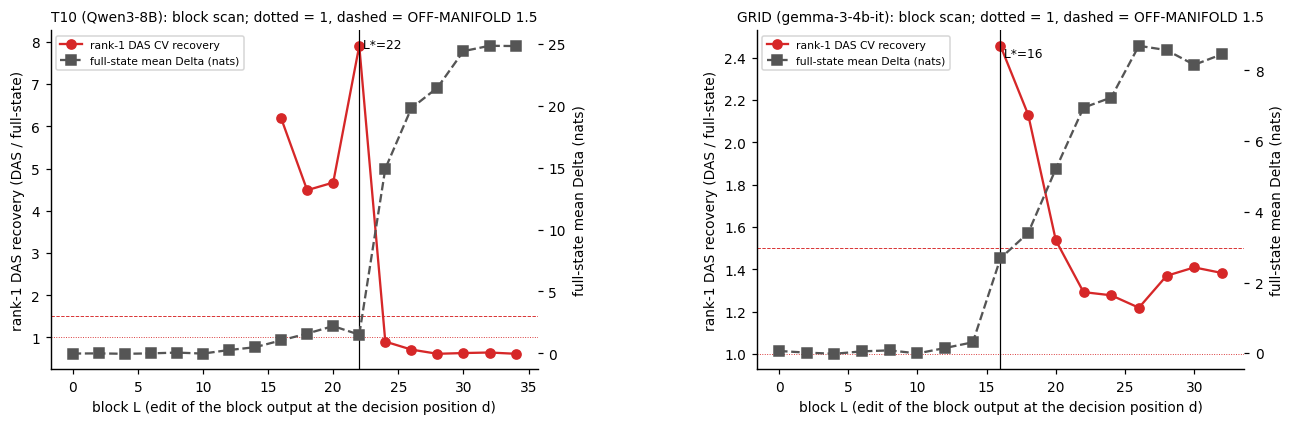

F2_recovery_by_rank


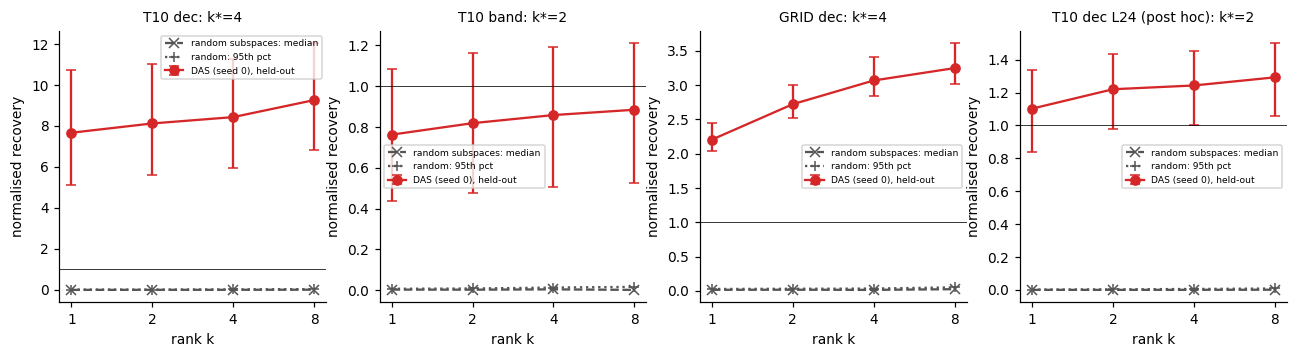

F4_generation


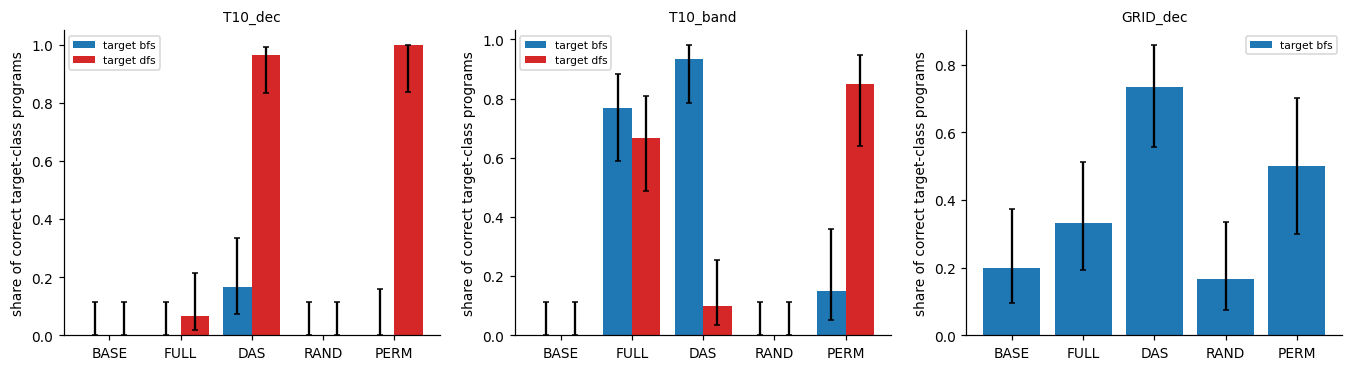

F5_mediation


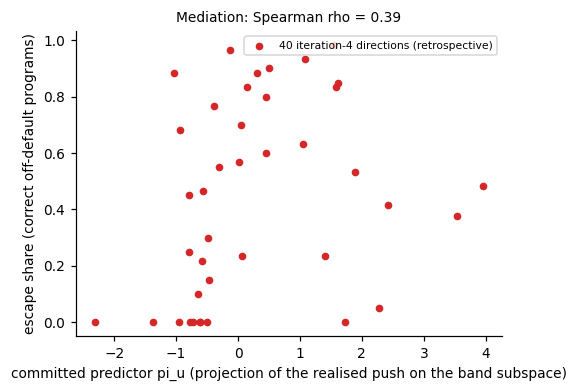

In [13]:
# ================================================================ src/figures8.py (results/*.json -> md; shown inline)
COL = {"bfs": "#1f77b4", "dfs": "#d62728", "union_find": "#2ca02c", "astar_gbfs": "#9467bd", "iddfs": "#8c564b",
       "twin": "#7f7f7f", "padtwin": "#bcbd22", "ban": "#ff7f0e", "top5": "#e377c2", "seed": "#17becf",
       "instr": "#000000", "p0": "#aaaaaa"}


def save(fig: Any, name: str) -> None:
    # original: fig.savefig(FIGS / f"{name}.pdf", bbox_inches="tight"); fig.savefig(FIGS / f"{name}.png", dpi=180,
    # bbox_inches="tight"); plt.close(fig) -- here the PNG goes to memory (lower dpi) and is displayed. The axis
    # labels are listed because matplotlib 3.10 (Colab) trims labels wider than their axes from the tight box.
    labels = [a.xaxis.label for a in fig.axes] + [a.yaxis.label for a in fig.axes]
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=110, bbox_inches="tight", bbox_extra_artists=labels)
    plt.close(fig)
    print(name)
    display(Image(buf.getvalue()))


def f1_scan() -> None:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.0))
    fig.subplots_adjust(wspace=0.45)
    for ax, unit in zip(axes, ("T10", "GRID")):
        p = md.get(f"scan_{unit}")                                      # results/scan_<unit>.json
        if p is None:
            ax.set_title(f"{unit}: scan not run")
            continue
        sc = {int(k): v for k, v in p.items()}
        L = sorted(sc)
        rec = [float(sc[l]["cv_median_recovery"]) if sc[l]["cv_median_recovery"] is not None else np.nan for l in L]
        full = [sc[l]["full_state_mean_delta_held96"] for l in L]
        ax.plot(L, rec, "o-", color="#d62728", label="rank-1 DAS CV recovery")
        ax.axhline(1.0, color="#d62728", lw=0.6, ls=":")
        ax.axhline(1.5, color="#d62728", lw=0.6, ls="--")
        ax.set_xlabel("block L (edit of the block output at the decision position d)")
        ax.set_ylabel("rank-1 DAS recovery (DAS / full-state)")
        ax2 = ax.twinx()
        ax2.plot(L, full, "s--", color="#555555", label="full-state mean Delta (nats)")
        ax2.set_ylabel("full-state mean Delta (nats)")
        d = md.get(f"dec_{unit}")                                       # results/dec_<unit>.json
        if d is not None:
            Ls = d["L_star"]
            ax.axvline(Ls, color="k", lw=0.8)
            ax.text(Ls, ax.get_ylim()[1] * 0.95, f" L*={Ls}", fontsize=8)
        ax.set_title(f"{unit} ({'Qwen3-8B' if unit == 'T10' else 'gemma-3-4b-it'}): block scan; dotted = 1, "
                     f"dashed = OFF-MANIFOLD 1.5", fontsize=9)
        h1, l1 = ax.get_legend_handles_labels()
        h2, l2 = ax2.get_legend_handles_labels()
        ax.legend(h1 + h2, l1 + l2, fontsize=7, loc="upper left")
    save(fig, "F1_scan_profile")


def f2_rank() -> None:
    sites = [("T10", "dec", "dec_T10"), ("T10", "band", "band_T10"),
             ("GRID", "dec", "dec_GRID"), ("T10", "dec L24 (post hoc)", "dec_T10_L24")]
    sites = [s for s in sites if md.get(s[2]) is not None]
    if not sites:
        return
    fig, axes = plt.subplots(1, len(sites), figsize=(3.6 * len(sites), 3.2), squeeze=False)
    for ax, (unit, site, p) in zip(axes[0], sites):
        d = md[p]
        ks = [1, 2, 4, 8]
        rr = [d["recovery_by_rank"][str(k)]["recovery"] for k in ks]
        lo = [d["recovery_by_rank"][str(k)]["ci95"][0] for k in ks]
        hi = [d["recovery_by_rank"][str(k)]["ci95"][1] for k in ks]
        ax.errorbar(ks, rr, yerr=[np.array(rr) - np.array(lo), np.array(hi) - np.array(rr)], fmt="o-",
                    color="#d62728", capsize=3, label="DAS (seed 0), held-out")
        med = [d["c1"][str(k)]["median"] for k in ks]
        p95 = [d["c1"][str(k)]["p95"] for k in ks]
        ax.plot(ks, med, "x--", color="#555555", label="random subspaces: median")
        ax.plot(ks, p95, "+:", color="#555555", label="random: 95th pct")
        ax.axhline(1.0, color="k", lw=0.5)
        ax.set_xscale("log", base=2)
        ax.set_xticks(ks)
        ax.set_xticklabels(ks)
        ax.set_xlabel("rank k")
        ax.set_ylabel("normalised recovery")
        ax.set_title(f"{unit} {site}: k*={d['k_star']}", fontsize=9)
        ax.legend(fontsize=6)
    save(fig, "F2_recovery_by_rank")


def f4_generation(an: dict[str, Any]) -> None:
    items = [(k, v) for k, v in an.items() if k.startswith("gen_")]
    if not items:
        return
    fig, axes = plt.subplots(1, len(items), figsize=(5 * len(items), 3.6), squeeze=False)
    for ax, (k, g) in zip(axes[0], items):
        arms = ["BASE", "FULL", "DAS", "RAND", "PERM"]
        x = np.arange(len(arms))
        w = 0.8 / max(1, len(g["classes"]))
        for j, (c, v) in enumerate(g["classes"].items()):
            sh = [(v["arms"].get(a) or {}).get("share") or 0 for a in arms]
            ci = [(v["arms"].get(a) or {}).get("wilson95") or [0, 0] for a in arms]
            lo = [s - (c_[0] or 0) for s, c_ in zip(sh, ci)]
            hi = [(c_[1] or 0) - s for s, c_ in zip(sh, ci)]
            ax.bar(x + j * w, sh, w, yerr=[lo, hi], capsize=2, color=COL.get(c, "#888"), label=f"target {c}")
        ax.set_xticks(x + w * (len(g["classes"]) - 1) / 2)
        ax.set_xticklabels(arms)
        ax.set_ylabel("share of correct target-class programs")
        ax.set_title(k.replace("gen_", ""), fontsize=9)
        ax.legend(fontsize=7)
    save(fig, "F4_generation")


def f5_mediation() -> None:
    m = md.get("mediation_T10")                                         # results/mediation_T10.json
    if m is None:
        return
    fig, ax = plt.subplots(figsize=(5, 3.6))
    xs = [v["pi"] for v in m["directions"].values() if v.get("escape_pooled") is not None]
    ys = [v["escape_pooled"] for v in m["directions"].values() if v.get("escape_pooled") is not None]
    ax.scatter(xs, ys, s=16, color="#d62728", label="40 iteration-4 directions (retrospective)")
    rho = (m.get("spearman_escape_pooled") or {}).get("rho")
    ax.set_xlabel("committed predictor pi_u (projection of the realised push on the band subspace)")
    ax.set_ylabel("escape share (correct off-default programs)")
    ax.set_title(f"Mediation: Spearman rho = {rho:.2f}" if rho is not None else "Mediation", fontsize=9)
    ax.legend(fontsize=7)
    save(fig, "F5_mediation")


f1_scan()
f2_rank()
f4_generation(res)
f5_mediation()

## 10. Results: the actual Deltas and the activation geometry

- **(a)** The per-pair evidence behind the OFF-MANIFOLD flag. Each point is one held-out (source, base) pair: x is
  the Delta of exchanging the whole block-22 state at the decision token, and y is the Delta of the rank-k\* DAS edit.
  BFS and DFS sources sit far above the identity line: a 4-dimensional edit moves the margin much more than the whole
  4096-dimensional state does. The union-find sources (whose base twins already pick DFS) sit near zero.
- **(b)** Recovery by rank, replayed here and as published, against random subspaces (c1).
- **(c, d)** Where the prompt groups sit in the fitted handle subspace (stored `results/geometry.json`). Every
  prompt's R_8 coordinates at (L\*, d), centred on the neutral twins, were embedded by metric MDS. The points are the
  group centroids of that embedding. Stars are the forced-algorithm classes, sized by how many test-passing programs
  of that class the unedited and source prompts produced.
  - In T10, three groups all sit together, away from every forced cluster: the neutral twins, the seed strings
    ("seed=d32qxk4nt43", "seed=(horse chair roof love)") and the novelty instructions ("Make a new algorithm.",
    plus a 2,000-word novelty brief). The five union-find bans ("ban") sit just outside them, toward the forced
    clusters.
  - In GRID, the prompt that prohibits the five most common algorithms ("top5") stays inside the twin cluster, on
    neither class's side.

  In this subspace, prompt-level "creativity" pushes do not move the model toward another algorithm.

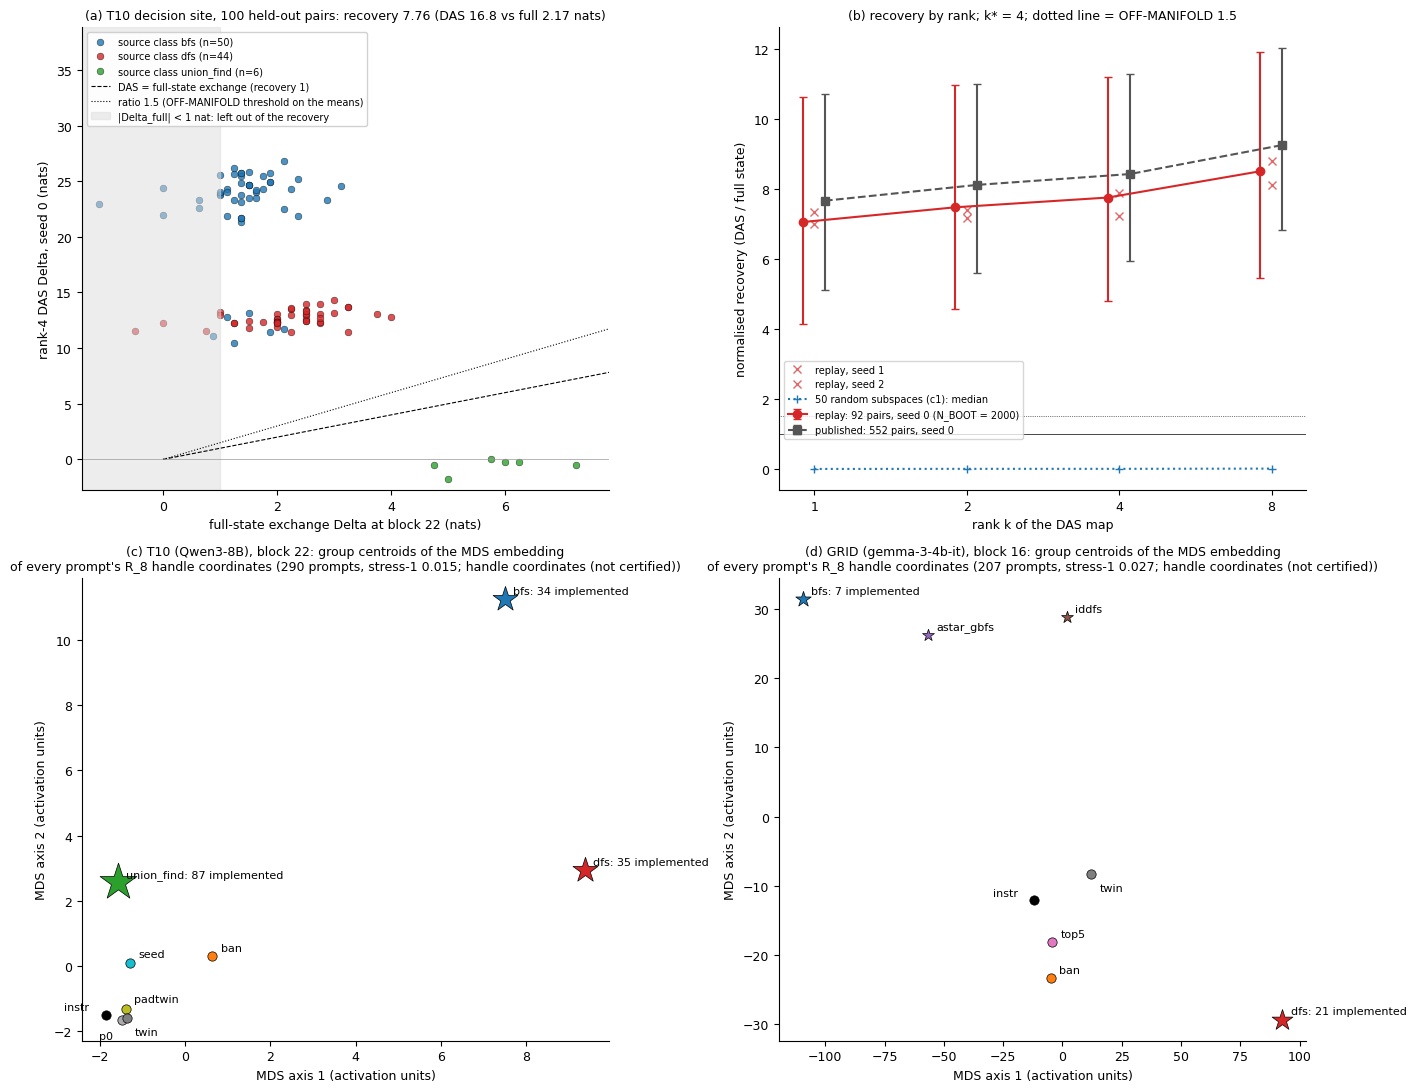

| quantity | this notebook | published run |
|---|---|---|
| T10 decision-site TF recovery at k* [95% CI] | 7.76 [4.80, 11.22] on 92 pairs | 8.43 [5.94, 11.30] on 552 pairs |
| k* | 4 | 4 |
| mean Delta, DAS vs full state (nats) | 16.8 vs 2.17 | 17.4 vs 2.06 |
| OFF-MANIFOLD flag | True | True |
| verdict T10-dec | NO HANDLE (replayed TF), NO HANDLE (stored TF) | NO HANDLE |
| verdicts T10-band / GRID-dec | SUFFICIENT HANDLE / SUFFICIENT HANDLE | SUFFICIENT HANDLE / SUFFICIENT HANDLE |
| K2 (p_K2) | DISCONFIRMED (0.037) | DISCONFIRMED (0.037) |
| T10 generation, target DFS: correct programs DAS / FULL / RAND / BASE (of 30) | stored | 29 / 2 / 0 / 0 |
| T10 generation, target BFS: correct (attempted BFS) DAS / FULL / RAND / BASE | stored | 5 / 0 / 0 / 0 (29 DAS attempts) |
| GRID generation, target BFS: DAS / FULL / RAND / BASE | stored | 22 / 10 / 5 / 6 |
| novel ('other') algorithms among correct programs | stored | 0 of 1857 |

In [14]:
d_full = {(r["src"], r["base"]): r["delta_full"] for r in tf_rows}
d_das = {(r["src"], r["base"]): r["delta"] for r in tf_rows if r["fit"] == "seed0" and r["rank_k"] == kstar}
c_src = {(r["src"], r["base"]): r["class_src"] for r in tf_rows}
pub = md["dec_T10"]
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

# (a) per-pair Deltas: DAS edit vs full-state exchange
ax = axes[0, 0]
for c in UNITS["T10"]["classes"]:
    ps = [p for p in held if c_src[p] == c]
    if ps:
        ax.scatter([d_full[p] for p in ps], [d_das[p] for p in ps], s=24, alpha=0.8, color=COL[c], edgecolor="k",
                   linewidth=0.3, label=f"source class {c} (n={len(ps)})")
x0, x1 = min(min(d_full.values()), 0.0) - 0.3, max(d_full.values()) * 1.08
xx = np.array([0.0, x1])
ax.plot(xx, xx, "k--", lw=0.8, label="DAS = full-state exchange (recovery 1)")
ax.plot(xx, OFF_MANIFOLD * xx, "k:", lw=0.8, label=f"ratio {OFF_MANIFOLD} (OFF-MANIFOLD threshold on the means)")
ax.axvspan(x0, 1.0, color="#dddddd", alpha=0.5, label="|Delta_full| < 1 nat: left out of the recovery")
ax.axhline(0, color="#999999", lw=0.5)
ax.set_xlim(x0, x1)
ax.set_ylim(min(min(d_das.values()), 0.0) - 1.0, max(d_das.values()) * 1.45)     # headroom for the legend
ax.set_xlabel(f"full-state exchange Delta at block {md['dec_T10']['L_star']} (nats)")
ax.set_ylabel(f"rank-{kstar} DAS Delta, seed 0 (nats)")
ax.set_title(f"(a) T10 decision site, {len(held)} held-out pairs: recovery {main['recovery']:.2f} "
             f"(DAS {main['mean_delta_edit']:.1f} vs full {main['mean_delta_full']:.2f} nats)", fontsize=9)
ax.legend(fontsize=7, loc="upper left", framealpha=0.9)

# (b) recovery by rank: this replay vs the published table
ax = axes[0, 1]
ks = np.array(RANKS)
rr = np.array([rec_rank[k]["recovery"] for k in RANKS])
lo = np.array([rec_rank[k]["ci95"][0] if rec_rank[k]["ci95"][0] is not None else rec_rank[k]["recovery"] for k in RANKS])
hi = np.array([rec_rank[k]["ci95"][1] if rec_rank[k]["ci95"][1] is not None else rec_rank[k]["recovery"] for k in RANKS])
ax.errorbar(ks * 0.95, rr, yerr=[rr - lo, hi - rr], fmt="o-", color="#d62728", capsize=3,
            label=f"replay: {main['n']} pairs, seed 0 (N_BOOT = {N_BOOT})")
pr = np.array([pub["recovery_by_rank"][str(k)]["recovery"] for k in RANKS])
plo = np.array([pub["recovery_by_rank"][str(k)]["ci95"][0] for k in RANKS])
phi = np.array([pub["recovery_by_rank"][str(k)]["ci95"][1] for k in RANKS])
ax.errorbar(ks * 1.05, pr, yerr=[pr - plo, phi - pr], fmt="s--", color="#555555", capsize=3,
            label=f"published: {pub['main']['n']} pairs, seed 0")
for sd in DEMO_SEEDS:
    if sd:
        ax.plot(ks, [rec_rank[f"seed{sd}"][k]["recovery"] for k in RANKS], "x", color="#d62728", alpha=0.7,
                label=f"replay, seed {sd}")
ax.plot(ks, [pub["c1"][str(k)]["median"] for k in RANKS], "+:", color="#1f77b4",
        label="50 random subspaces (c1): median")
ax.axhline(1.0, color="k", lw=0.5)
ax.axhline(OFF_MANIFOLD, color="k", lw=0.5, ls=":")
ax.set_xscale("log", base=2)
ax.set_xticks(ks)
ax.set_xticklabels(ks)
ax.set_xlabel("rank k of the DAS map")
ax.set_ylabel("normalised recovery (DAS / full state)")
ax.set_title(f"(b) recovery by rank; k* = {kstar}; dotted line = OFF-MANIFOLD {OFF_MANIFOLD}", fontsize=9)
ax.legend(fontsize=7, loc="lower left", bbox_to_anchor=(0.0, 0.1))

# (c, d) stored geometry: group centroids of the metric-MDS embedding of every prompt's R_8 coordinates
LABEL_OFFSET = {"twin": (6, -12), "padtwin": (6, 5), "p0": (-16, -14), "instr": (-30, 3), "seed": (6, 4)}
for ax, unit, tag in ((axes[1, 0], "T10", "(c)"), (axes[1, 1], "GRID", "(d)")):
    g = md["geometry"][unit]
    for grp, (x, y) in g["group_centroids_mds"].items():
        n_impl = g["implemented_counts"].get(grp, 0)
        is_cls = grp in ("bfs", "dfs", "union_find", "astar_gbfs", "iddfs")
        ax.scatter([x], [y], s=(80 + 8 * n_impl) if is_cls else 45, marker="*" if is_cls else "o",
                   color=COL.get(grp, "#333333"), edgecolor="k", linewidth=0.5, zorder=3)
        lab = f"{grp}: {n_impl} implemented" if grp in g["implemented_counts"] else grp
        ax.annotate(lab, (x, y), fontsize=8, xytext=LABEL_OFFSET.get(grp, (6, 4)), textcoords="offset points")
    ax.set_xlabel("MDS axis 1 (activation units)")
    ax.set_ylabel("MDS axis 2 (activation units)")
    ax.set_title(f"{tag} {unit} ({'Qwen3-8B' if unit == 'T10' else 'gemma-3-4b-it'}), block {g['L']}: group centroids "
                 f"of the MDS embedding\nof every prompt's R_8 handle coordinates ({g['n_prompts']} prompts, "
                 f"stress-1 {g['mds_stress1']:.3f}; {g['title']})", fontsize=9)
fig.tight_layout()
plt.show()

# summary: this notebook vs the published run
g10 = md["gen_T10_dec"]["classes"]
ggr = md["gen_GRID_dec"]["classes"]
arms4 = ("DAS", "FULL", "RAND", "BASE")
summary = [
    "| quantity | this notebook | published run |", "|---|---|---|",
    f"| T10 decision-site TF recovery at k* [95% CI] | {main['recovery']:.2f} [{_f(main['ci95'][0])}, "
    f"{_f(main['ci95'][1])}] on {main['n']} pairs | {pub['main']['recovery']:.2f} [{pub['main']['ci95'][0]:.2f}, "
    f"{pub['main']['ci95'][1]:.2f}] on {pub['main']['n']} pairs |",
    f"| k* | {kstar} | {pub['k_star']} |",
    f"| mean Delta, DAS vs full state (nats) | {main['mean_delta_edit']:.1f} vs {main['mean_delta_full']:.2f} | "
    f"{pub['main']['mean_delta_edit']:.1f} vs {pub['main']['mean_delta_full']:.2f} |",
    f"| OFF-MANIFOLD flag | {off_manifold_flag} | {pub['off_manifold_flag']} |",
    f"| verdict T10-dec | {v_replay['verdict']} (replayed TF), {verdicts['T10-dec']['verdict']} (stored TF) | "
    f"{md['verdicts']['T10-dec']['verdict']} |",
    f"| verdicts T10-band / GRID-dec | {verdicts['T10-band']['verdict']} / {verdicts['GRID-dec']['verdict']} | "
    f"{md['verdicts']['T10-band']['verdict']} / {md['verdicts']['GRID-dec']['verdict']} |",
    f"| K2 (p_K2) | {res['K2']['status']} ({res['K2']['p_K2']:.3f}) | {md['K2']['status']} ({md['K2']['p_K2']:.3f}) |",
    f"| T10 generation, target DFS: correct programs DAS / FULL / RAND / BASE (of 30) | stored | "
    f"{' / '.join(str(g10['dfs']['arms'][a]['correct_target']) for a in arms4)} |",
    f"| T10 generation, target BFS: correct (attempted BFS) DAS / FULL / RAND / BASE | stored | "
    f"{' / '.join(str(g10['bfs']['arms'][a]['correct_target']) for a in arms4)} "
    f"({g10['bfs']['arms']['DAS']['attempted_target']} DAS attempts) |",
    f"| GRID generation, target BFS: DAS / FULL / RAND / BASE | stored | "
    f"{' / '.join(str(ggr['bfs']['arms'][a]['correct_target']) for a in arms4)} |",
    f"| novel ('other') algorithms among correct programs | stored | "
    f"{sum(u['n_candidates'] for u in md['novelty_audit']['units'].values())} of "
    f"{sum(u['n_correct_programs'] for u in md['novelty_audit']['units'].values())} |",
]
display(Markdown("\n".join(summary)))

## Scaling back to the full run, and how to read the result

**Larger replay.** The notebook already uses the original bootstrap settings (`N_BOOT = 2000`, `N_BOOT_CLASS = 500`,
`DEMO_SEEDS = (0, 1, 2)`) on all 100 shipped pairs. For the run's full 600 held-out pairs, load the artifact's
`full_method_out.json`, put its `T10_dec_teacher_forced` dataset (same format) in place of `data["datasets"][0]`,
and set `N_PAIRS = 600`. The replay then reproduces `results/dec_T10.json`: recovery
7.67 / 8.12 / 8.43 / 9.26 at ranks 1 / 2 / 4 / 8, with the same CIs. The stored Deltas are rounded to 4 decimals, so
the agreement is to about four decimals.

**The GPU stages.** Inside the artifact folder:

```bash
uv venv .venv --python=3.12 && uv pip install --python .venv/bin/python -r pyproject.toml
hf download Qwen/Qwen3-8B --revision b968826d9c46dd6066d109eabc6255188de91218
hf download google/gemma-3-4b-it --revision 093f9f388b31de276ce2de164bdc2081324b9767
.venv/bin/python method.py              # everything: about 3.5 h on one 23 GB L4 (3.2 GPU-hours)
.venv/bin/python method.py --cpu-only   # the analysis / tables / figures / audit replayed in this notebook
```

**Reading it.** The rank-4 edit at the decision token is a strong, reproducible handle, and it works in generation
(29/30 correct DFS programs). It is not the model's own algorithm variable, for three reasons:

1. **Specificity (c2, c3).** It works almost as well when fitted to the wrong labels or to an untrained network.
2. **Location (OFF-MANIFOLD, c4, c5).** It acts where exchanging the whole state barely matters: Delta 17 vs 2 nats.
3. **Coherence.** BFS edits in Qwen produce BFS openings but mostly broken programs (5 of 29 pass the hidden tests).

Random pushes from iteration 4 that also change the algorithm do not pass through these subspaces (clamp removal
-0.01). No edit, push or clamp produced a novel algorithm: 0 'other' among 1,857 correct programs.